# TruthLens: Deep Learning Pipeline for Fake News Detection

Welcome to the **TruthLens** project documentation. This repository outlines a comprehensive deep learning pipeline designed to identify and classify deceptive news content by leveraging advanced Natural Language Processing (NLP) architectures.

---

## **Project Overview**

The **TruthLens** project aims to distinguish between authentic and fabricated news articles by evaluating linguistic patterns, structural biases, and sentiment markers. By implementing a multi-stage pipeline—ranging from traditional statistical baselines to state-of-the-art transformer models—this project provides a robust framework for automated misinformation detection.





## Phase 1 — Setup and Imports

In [1]:
import os, re, string, warnings, time
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from wordcloud import WordCloud
import matplotlib.patches as mpatches

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Deep learning stack: pure PyTorch (no TensorFlow / Keras anywhere in this notebook)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings('ignore')

PALETTE  = {'Fake': '#E74C3C', 'Real': '#2ECC71'}
BG_COLOR = '#F8F9FA'
plt.rcParams.update({
    'figure.facecolor': BG_COLOR,
    'axes.facecolor':   BG_COLOR,
    'font.family':      'DejaVu Sans',
    'axes.spines.top':  False,
    'axes.spines.right': False,
})
sns.set_palette([PALETTE['Fake'], PALETTE['Real']])

for pkg in ['stopwords', 'punkt', 'punkt_tab', 'wordnet']:
    nltk.download(pkg, quiet=True)

print('Libraries loaded.')
print(f'PyTorch      : {torch.__version__}')
print(f'GPU available: {torch.cuda.is_available()}')


Libraries loaded.
PyTorch      : 2.5.1+cu121
GPU available: True


## 2. DATA LOADING & MERGING

## Phase 2 — Load Dataset (50% Sample)

In [2]:
import pandas as pd

# 1. Load datasets from your local Windows paths
file_true = pd.read_csv(
    r"C:\Users\User1\Downloads\Fake news\True.csv",
    engine='python',
    encoding='utf-8',
    on_bad_lines='warn'
)

file_fake = pd.read_csv(
    r"C:\Users\User1\Downloads\Fake news\Fake.csv",
    engine='python',
    encoding='utf-8',
    on_bad_lines='warn'
)

# 2. Add labels and source columns
file_true['label'] = 1
file_true['source'] = 'Real'

file_fake['label'] = 0
file_fake['source'] = 'Fake'

# 3. Combine both datasets into one dataframe
df = pd.concat(
    [file_true, file_fake],
    axis=0,
    ignore_index=True
)

# 4. Shuffle the dataset randomly
df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# 5. Create readable label names
df['label_name'] = df['label'].map({
    1: 'Real',
    0: 'Fake'
})

# 6. Print dataset information
print(f"Dataset shape: {df.shape}")
print(f"Fake articles: {len(file_fake)}, Real articles: {len(file_true)}")

# 7. Display first 5 rows
df.head()

Dataset shape: (38219, 7)
Fake articles: 17295, Real articles: 20924


,title,text,subject,date,label,source,label_name
0,(Video) Donald Trump YUGE! Rally At Oklahoma S...,Presidential candidate and front-runner Donald...,politics,"Sep 26, 2015",0,Fake,Fake
1,"Immigration overhaul backers sing, dance, chan...","Dancing, singing, chanting and cheering, thron...",politicsNews,"April 18, 2016",1,Real,Real
2,U.S. Senate Leader McConnell opposes lifting R...,The U.S. Senate’s Republican Majority Leader M...,politicsNews,"January 27, 2017",1,Real,Real
3,"Coalition says fewer than 3,000 IS fighters re...",The United States-led international coalition ...,worldnews,"December 5, 2017",1,Real,Real
4,Russia criticizes U.S. for 'anti-Cuban' approa...,The Russian Foreign Ministry said on Sunday th...,politicsNews,"June 18, 2017",1,Real,Real


## Phase 3 — Exploratory Data Analysis

### 3.1 Subject Classification


In [3]:
#lenth
df['text'].apply(lambda x: len(str(x).split()))
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))
df[['text', 'text_length']].head()


,text,text_length
0,Presidential candidate and front-runner Donald...,32
1,"Dancing, singing, chanting and cheering, thron...",448
2,The U.S. Senate’s Republican Majority Leader M...,85
3,The United States-led international coalition ...,396
4,The Russian Foreign Ministry said on Sunday th...,85


In [4]:
#Average text length
average_length = df['text_length'].mean()
print("Average text length:", average_length)

Average text length: 403.61838352651824


In [5]:
# ── Basic info ───────────────────────────────────────────────────────────────
print('=== Dataset Info ===')
print(df.info())
print('\n=== Missing values ===')
print(df.isnull().sum())
print('\n=== Label distribution ===')
print(df['label_name'].value_counts())

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 38219 entries, 0 to 38218
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   title        38219 non-null  str  
 1   text         38219 non-null  str  
 2   subject      38219 non-null  str  
 3   date         38219 non-null  str  
 4   label        38219 non-null  int64
 5   source       38219 non-null  str  
 6   label_name   38219 non-null  str  
 7   text_length  38219 non-null  int64
dtypes: int64(2), str(6)
memory usage: 96.3 MB
None

=== Missing values ===
title          0
text           0
subject        0
date           0
label          0
source         0
label_name     0
text_length    0
dtype: int64

=== Label distribution ===
label_name
Real    20924
Fake    17295
Name: count, dtype: int64


## 3.2 Class Distribution

In [6]:
SUBJECT_MAP = {
    'News':           'General News',
    'politics':       'Political News',
    'left-news':      'Left-Wing News',
    'Government News':'Government & Policy',
    'US_News':        'US News',
    'Middle-east':    'Middle East News',
    'politicsNews':   'Political News',
    'worldnews':      'World News',
}
df['category'] = df['subject'].map(SUBJECT_MAP).fillna(df['subject'])
print(df.groupby(['subject', 'category']).size().rename('count').reset_index().to_string(index=False))


        subject            category  count
Government News Government & Policy    881
    Middle-east    Middle East News    387
           News        General News   9050
        US_News             US News    396
      left-news      Left-Wing News   2370
       politics      Political News   4211
   politicsNews      Political News  11069
      worldnews          World News   9855


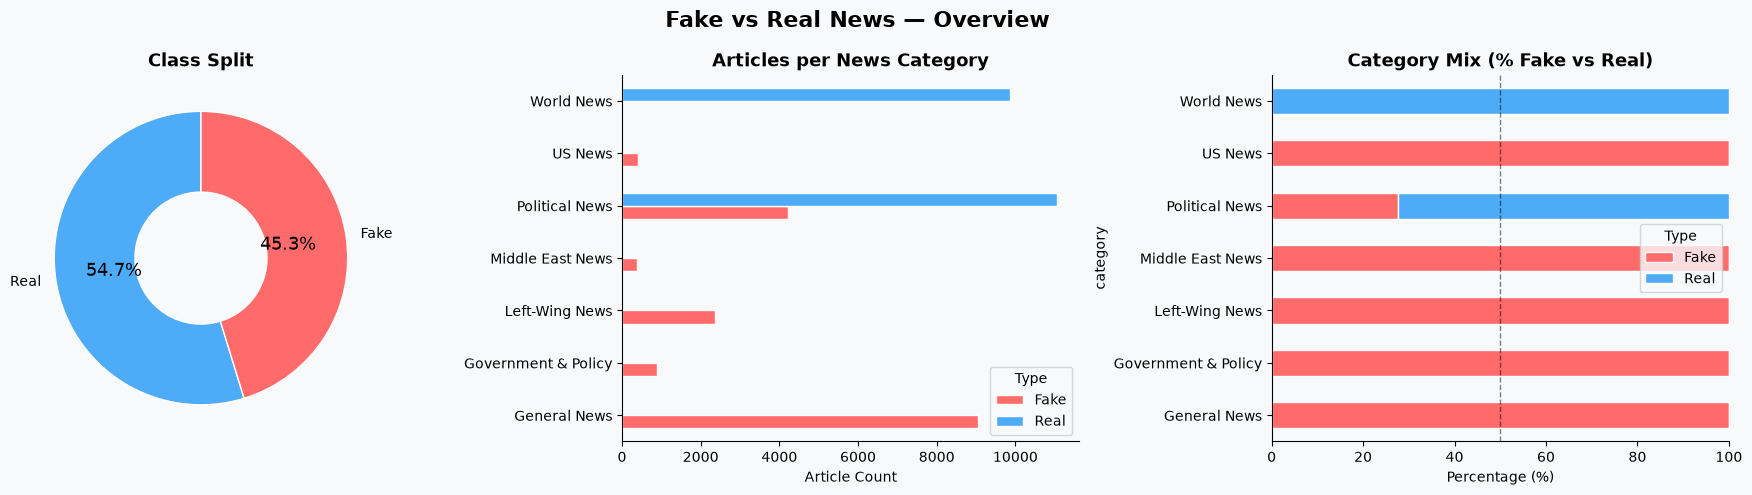

In [7]:
# Example palette
PALETTE = {
    'Fake': '#ff6b6b',
    'Real': '#4dabf7'
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Fake vs Real News — Overview', fontsize=16, fontweight='bold')

# ===== Pie Chart =====
counts = df['source'].value_counts()
labels = counts.index.tolist()
colors = [PALETTE[l] for l in labels]

wedges, _, autotexts = axes[0].pie(
    counts,
    labels=labels,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    wedgeprops=dict(width=0.55, edgecolor='white')
)

for at in autotexts:
    at.set_fontsize(13)

axes[0].set_title('Class Split', fontsize=13, fontweight='bold')

# ===== Articles per Category =====
cat_df = df.groupby(['category', 'source']).size().unstack(fill_value=0)

cat_df.plot(
    kind='barh',
    ax=axes[1],
    color=[PALETTE['Fake'], PALETTE['Real']],
    edgecolor='white'
)

axes[1].set_title('Articles per News Category', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Article Count')
axes[1].set_ylabel('')
axes[1].legend(title='Type')

# ===== Percentage Mix =====
cat_pct = cat_df.div(cat_df.sum(axis=1), axis=0) * 100

cat_pct.plot(
    kind='barh',
    stacked=True,
    ax=axes[2],
    color=[PALETTE['Fake'], PALETTE['Real']],
    edgecolor='white'
)

axes[2].set_title('Category Mix (% Fake vs Real)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Percentage (%)')
axes[2].axvline(50, color='black', linestyle='--', linewidth=1, alpha=0.5)
axes[2].legend(title='Type')

plt.tight_layout()

# Save image
plt.savefig('eda_class_distribution.png', dpi=150, bbox_inches='tight')

# Show plots
plt.show()

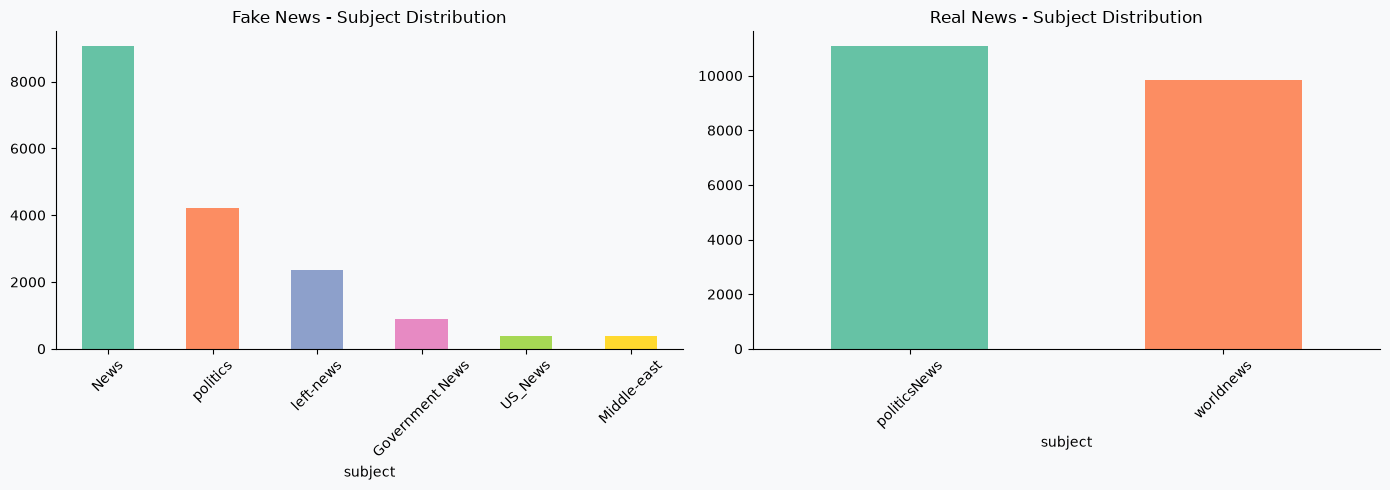

In [8]:
# --- 3.3 Subject Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, (name, group) in enumerate(df.groupby('label')):
    group['subject'].value_counts().plot(kind='bar', ax=axes[i],
        color=sns.color_palette("Set2"))
    axes[i].set_title(f"{'Real' if name == 1 else 'Fake'} News - Subject Distribution")
    axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### 3.3 Article Length Analysis

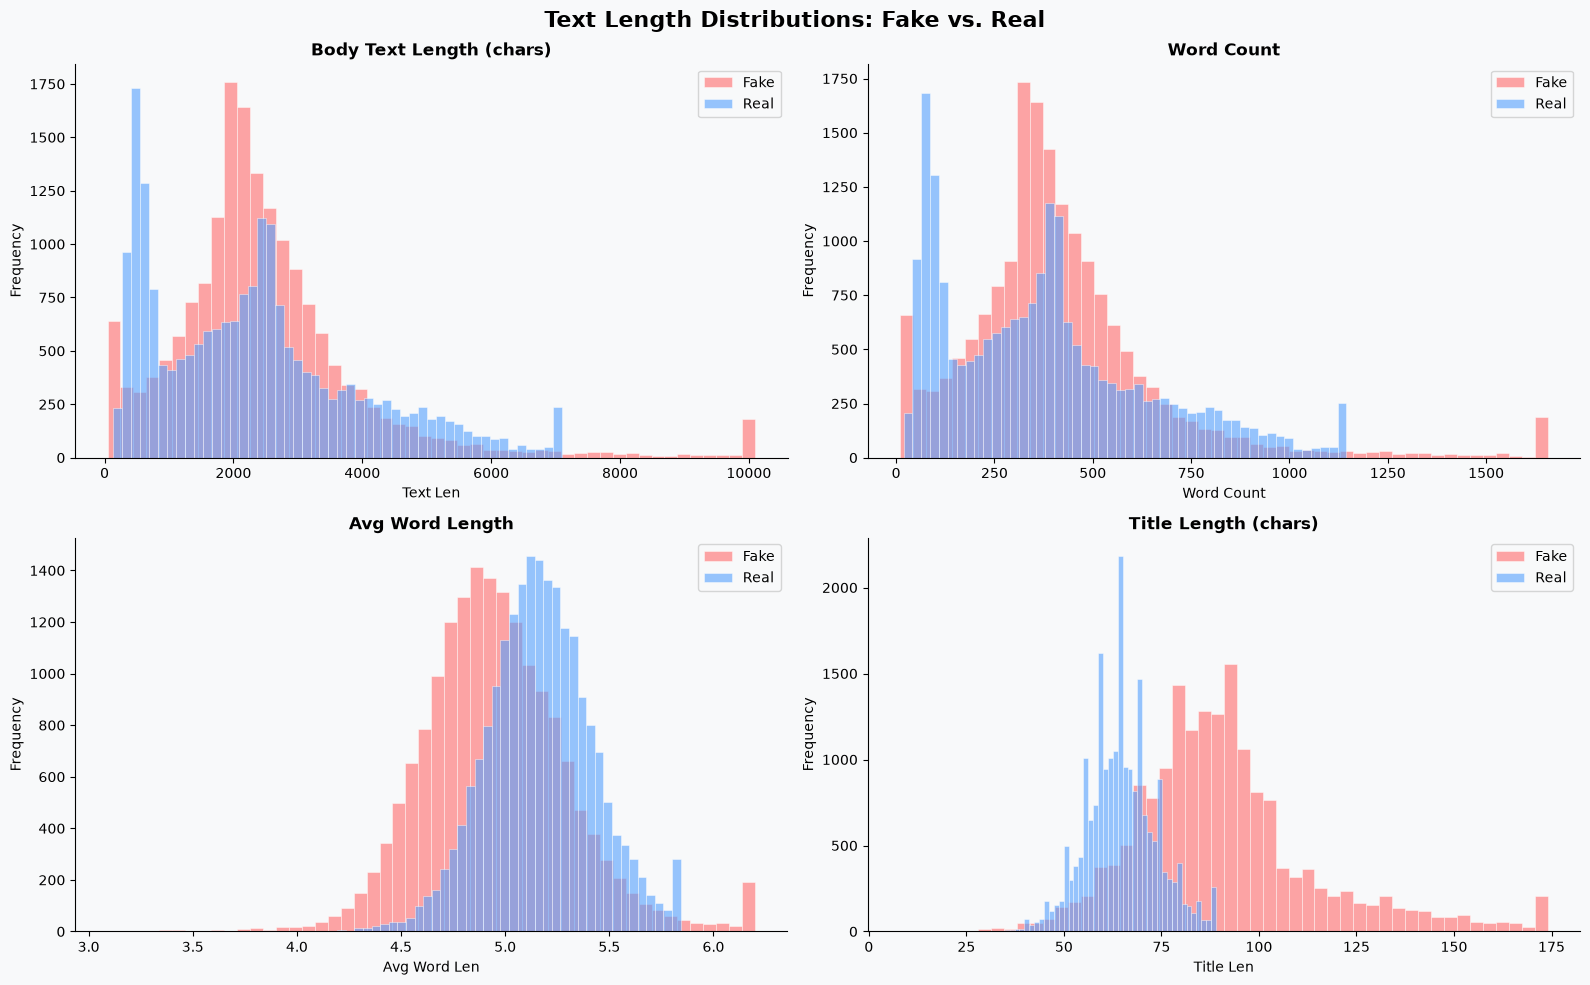


==================== Comprehensive Descriptive Statistics by Class ====================
label_name              Fake      Real
text_len     count  17295.00  20924.00
             mean    2573.25   2362.35
             std     2197.44   1684.16
             min       46.00    129.00
             25%     1679.50    901.75
             50%     2245.00   2201.50
             75%     3016.50   3207.00
             max    51794.00  29781.00
word_count   count  17295.00  20924.00
             mean     429.20    382.48
             std      354.40    273.86
             min       10.00     19.00
             25%      281.00    147.00
             50%      378.00    357.00
             75%      505.00    520.00
             max     8135.00   5172.00
avg_word_len count  17295.00  20924.00
             mean       4.96      5.17
             std        0.47      0.26
             min        3.09      3.78
             25%        4.73      5.00
             50%        4.93      5.16
             7

In [9]:
# 1. Define colors to match the timeline palette (Fake = Coral Red, Real = Sky Blue)
PALETTE = {'Fake': '#ff6b6b', 'Real': '#54a0ff'}

# 2. Clean data and compute features safely against missing values (NaN)
df['text_clean']  = df['text'].fillna('')
df['title_clean'] = df['title'].fillna('')

# Calculate basic text length features
df['text_len']    = df['text_clean'].str.len()
df['word_count']  = df['text_clean'].str.split().str.len()

df = df[df['word_count'] > 0]


df['title_len']   = df['title_clean'].str.len()
df['title_wc']    = df['title_clean'].str.split().str.len()

# Calculate advanced linguistic features safely to prevent division-by-zero errors
df['avg_word_len'] = df['text_clean'].apply(lambda x: np.mean([len(w) for w in x.split()]) if len(x.split()) > 0 else 0)
df['excl_count']   = df['text_clean'].str.count('!')
df['caps_ratio']   = df['text_clean'].apply(lambda x: sum(1 for c in x if c.isupper()) / max(len(x), 1))

# Standardize the target label column name based on availability
if 'source' in df.columns:
    df['label_name'] = df['source']
else:
    df['label_name'] = df['label'].map({0: 'Fake', 1: 'Real'})

# 3. Create the enhanced visualization grid (2x2 Grid)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
features = ['text_len', 'word_count', 'avg_word_len', 'title_len']
titles   = ['Body Text Length (chars)', 'Word Count', 'Avg Word Length', 'Title Length (chars)']

# Plot distributions for each feature, clipping outliers for better readability
for ax, feat, title in zip(axes.flat, features, titles):
    for lbl in ['Fake', 'Real']:
        if lbl in df['label_name'].unique():
            subset = df[df['label_name'] == lbl][feat]
            # Clip at 99th percentile to exclude extreme outliers and keep charts scannable
            ax.hist(subset.clip(upper=subset.quantile(0.99)), bins=50,
                    alpha=0.6, color=PALETTE[lbl], label=lbl, edgecolor='white', linewidth=0.5)

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(feat.replace('_', ' ').title())
    ax.set_ylabel('Frequency')
    ax.legend()

# Configure overall layout and save the high-resolution image
plt.suptitle('Text Length Distributions: Fake vs. Real', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('eda_text_length_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# 4. Print the comprehensive descriptive statistics report (.describe)
print('\n' + '='*20 + ' Comprehensive Descriptive Statistics by Class ' + '='*20)
stat_features = ['text_len', 'word_count', 'avg_word_len', 'caps_ratio', 'excl_count']
print(df.groupby('label_name')[stat_features].describe().T.round(2))

### 3.4 Word Clouds — Fake vs Real

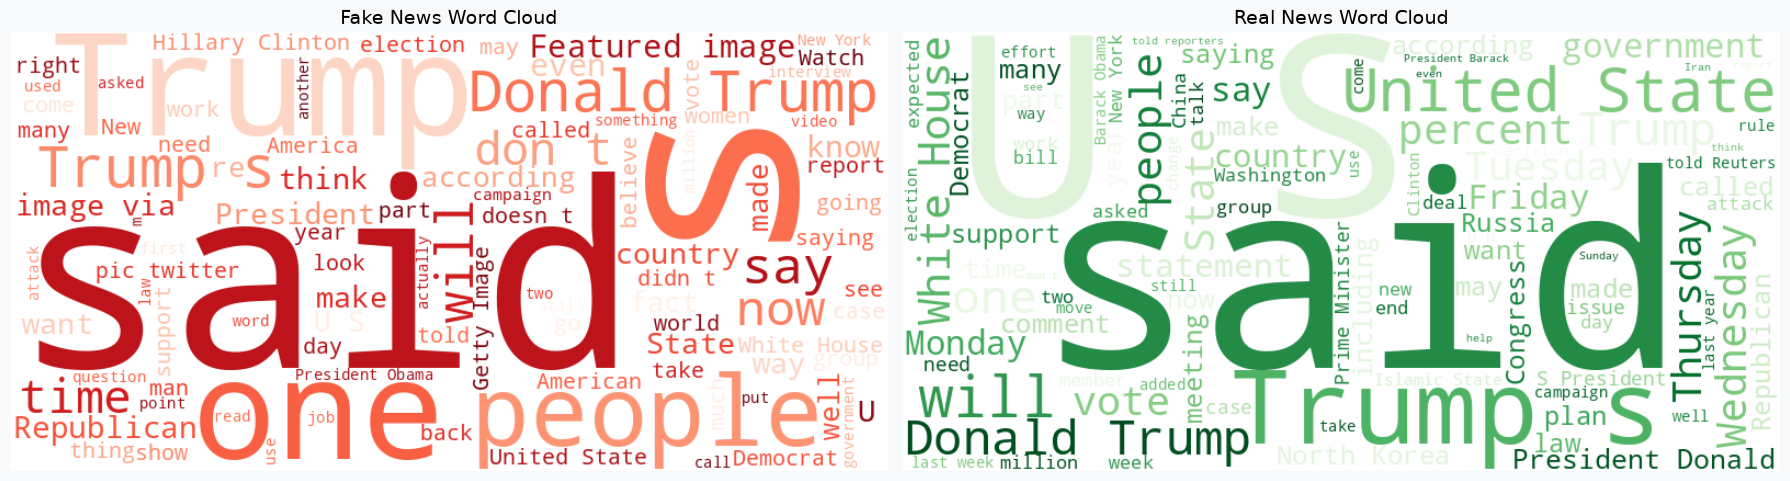

In [10]:
# --- 3.7 Word Cloud ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for i, label in enumerate([0, 1]):
    text = ' '.join(df[df['label'] == label]['text'].values)
    wc = WordCloud(width=800, height=400, max_words=100,
                   background_color='white',
                   colormap='Reds' if label == 0 else 'Greens').generate(text)
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(f"{'Fake' if label == 0 else 'Real'} News Word Cloud", fontsize=14)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

### 3.5 Top N-grams Analysis

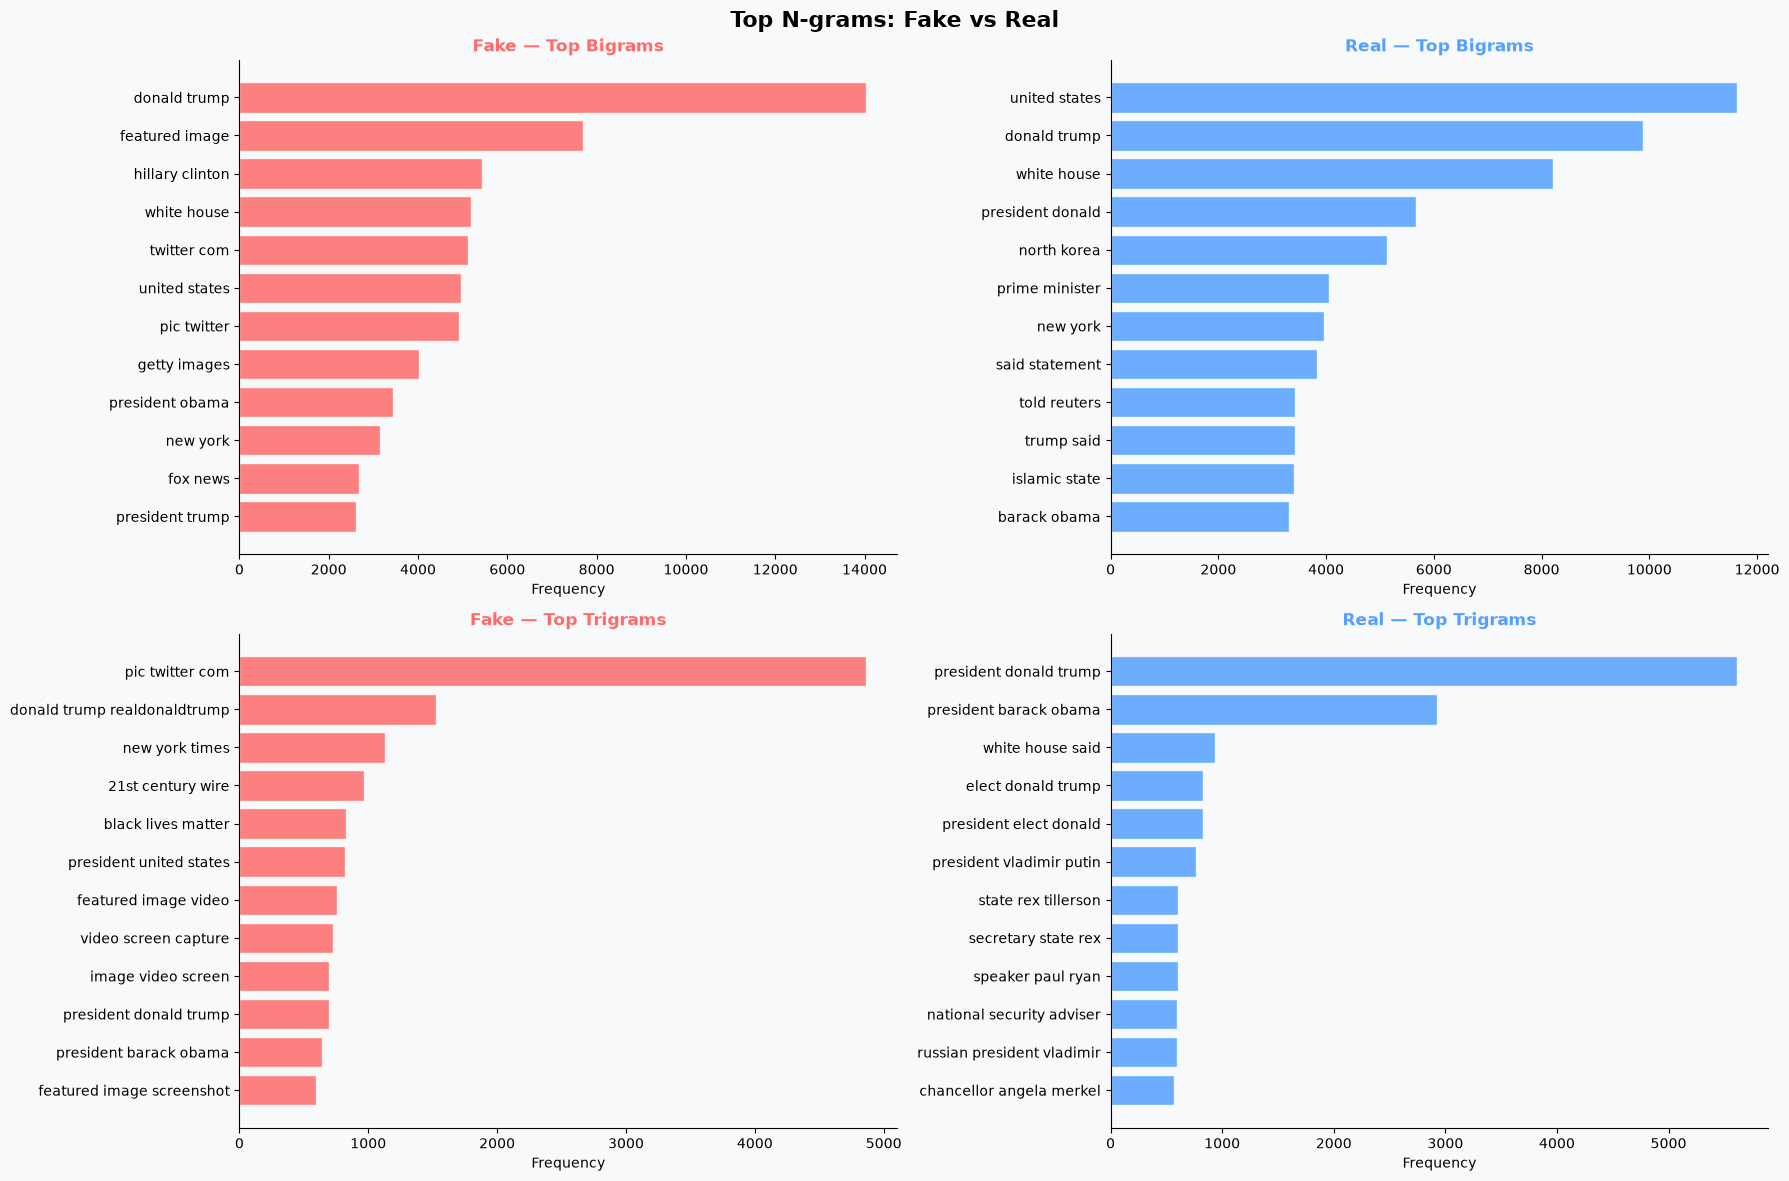

In [11]:
# --- 3.6 Top N-grams ---
def top_ngrams(corpus, n=2, top_k=15):
    vec = CountVectorizer(ngram_range=(n, n), stop_words='english',
                          max_features=5000).fit(corpus)
    bag = vec.transform(corpus)
    sums = bag.sum(axis=0)
    words = [(word, sums[0, idx]) for word, idx in vec.vocabulary_.items()]
    return sorted(words, key=lambda x: x[1], reverse=True)[:top_k]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Top N-grams: Fake vs Real', fontsize=16, fontweight='bold')

for row, n, label in [(0, 2, 'Bigrams'), (1, 3, 'Trigrams')]:
    for col, lbl in enumerate(['Fake', 'Real']):
        corpus = df[df['source'] == lbl]['text'].fillna('').values
        ngrams = top_ngrams(corpus, n=n, top_k=12)
        words, freqs = zip(*ngrams)
        y_pos = range(len(words))
        axes[row][col].barh(list(y_pos), list(freqs),
                            color=PALETTE[lbl], edgecolor='white', alpha=0.85)
        axes[row][col].set_yticks(list(y_pos))
        axes[row][col].set_yticklabels(list(words))
        axes[row][col].invert_yaxis()
        axes[row][col].set_title(f'{lbl} — Top {label}',
                                  fontsize=12, fontweight='bold', color=PALETTE[lbl])
        axes[row][col].set_xlabel('Frequency')

plt.tight_layout()
plt.savefig('eda_ngrams.png', dpi=150, bbox_inches='tight')
plt.show()


### 3.6 Publication Timeline

Source distribution in valid date range:
source
Fake    8306
Real     898
Name: count, dtype: int64


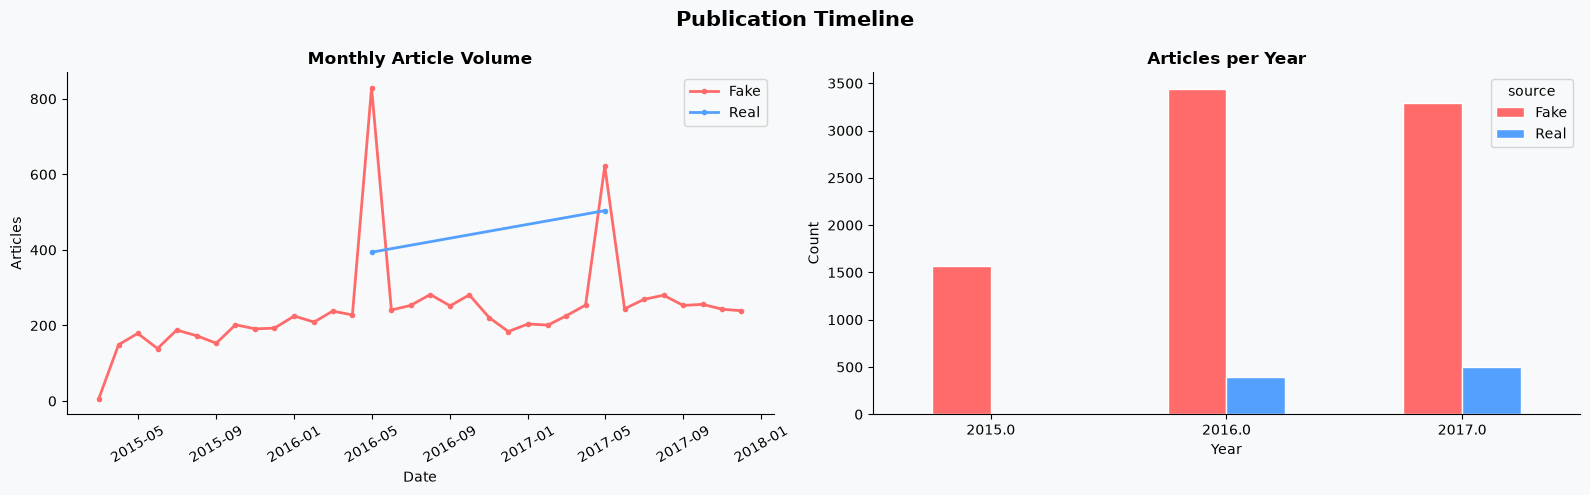

In [12]:
# 1. Convert the column to string type first to prevent the AttributeError
df['date'] = df['date'].astype(str).str.strip()

# 2. Parse text dates into datetime objects, setting unparseable rows to NaT (Not a Time)
df['date_parsed'] = pd.to_datetime(df['date'], errors='coerce')
df['year']  = df['date_parsed'].dt.year
df['month'] = df['date_parsed'].dt.month

# 3. Filter dataset to include only valid years between 2015 and 2018
valid = df[df['year'].between(2015, 2018)]
print("Source distribution in valid date range:")
print(valid['source'].value_counts())

# 4. Generate the visualization timeline if valid data is present
if len(valid) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle('Publication Timeline', fontsize=15, fontweight='bold')

    # Plot 1: Monthly Trend Line Chart
    for lbl, grp in valid.groupby('source'):
        monthly = grp.groupby(['year', 'month']).size().reset_index(name='count')
        monthly['date'] = pd.to_datetime(
            monthly['year'].astype(int).astype(str) + '-' +
            monthly['month'].astype(int).astype(str).str.zfill(2))
        axes[0].plot(monthly['date'], monthly['count'],
                      label=lbl, color=PALETTE[lbl], linewidth=2, marker='o', markersize=3)

    axes[0].set_title('Monthly Article Volume', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Date')
    axes[0].set_ylabel('Articles')
    axes[0].legend()
    axes[0].tick_params(axis='x', rotation=30)

    # Plot 2: Yearly Distribution Bar Chart
    yr = valid.groupby(['year', 'source']).size().unstack(fill_value=0)
    yr.plot(kind='bar', ax=axes[1], color=[PALETTE['Fake'], PALETTE['Real']], edgecolor='white')
    axes[1].set_title('Articles per Year', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Year')
    axes[1].set_ylabel('Count')
    axes[1].tick_params(axis='x', rotation=0)

    # Final layout adjustments and saving the figure
    plt.tight_layout()
    plt.savefig('eda_timeline.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("No valid dates found in 2015-2018 range.")

## Phase 4 — Data Cleaning and Preprocessing

In [13]:
STOPWORDS_NLP = set(stopwords.words('english'))
lemmatizer    = WordNetLemmatizer()

# Step 1: Remove rows with missing critical fields
df = df.dropna(subset=['text']).copy()
df['title'] = df['title'].fillna('')
df['text']  = df['text'].fillna('')

# Step 2: Remove near-empty articles
df = df[df['text'].str.split().str.len() >= 10].reset_index(drop=True)

# Step 3: Combine title + body into a temporary column before cleaning
df['content'] = df['title'] + ' ' + df['text']


# Step 4: NEW CLEANING FUNCTION (merged version)
def clean_text(text):
    if not isinstance(text, str):
        return ''

    # Prevent leak: Remove Reuters source patterns to stop shortcut learning
    text = re.sub(r'^.*?Reuters\s*-\s*', '', text)
    text = re.sub(r'\bReuters\b[^\w]*', '', text, flags=re.IGNORECASE)

    # Standard text cleaning transformations
    text = text.lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'\W', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Step 5: Apply cleaning functions on temporary column
df['content'] = df['content'].apply(clean_text)


# Step 6: NLP preprocessing (stopwords + lemmatization)
def preprocess(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ''

    tokens = text.split()
    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t not in STOPWORDS_NLP and len(t) > 2
    ]

    return ' '.join(tokens)


print("Applying text preprocessing...")
# Save the ultimate cleaned result directly back to the original 'text' column
df['text'] = df['content'].apply(preprocess)


# Drop temporary column to release system memory
df.drop(columns=['content'], inplace=True)


# Step 7: Remove empty rows after cleaning
df = df[df['text'].str.strip().str.len() > 0].reset_index(drop=True)

# Step 8: Remove duplicates based on the overwritten 'text' column
before = len(df)
df = df.drop_duplicates(subset=['text']).reset_index(drop=True)

print(f"Duplicates removed : {before - len(df)}")
print(f"Dataset shape      : {df.shape}")


# Step 9: Sanity checks
sample = ' '.join(df['text'].sample(min(200, len(df)), random_state=42))

# FIX: Extraction of regex check to avoid backslash (\s) inside f-string expression
has_symbols = bool(re.search(r'[^a-z0-9\s]', sample))

print("\nSanity checks on cleaned text:")
print(f"  URLs remaining    : {'YES - fix needed' if 'http' in sample or 'www.' in sample else 'None'}")
print(f"  Symbols remaining : {'YES - fix needed' if has_symbols else 'None'}")
print(f"  Capital letters   : {'YES - fix needed' if re.search(r'[A-Z]', sample) else 'None'}")

short = [w for w in sample.split() if len(w) < 3]
print(f"  Short tokens (<3) : {'YES - fix needed' if short else 'None'}")

Applying text preprocessing...
Duplicates removed : 1
Dataset shape      : (38218, 21)

Sanity checks on cleaned text:
  URLs remaining    : YES - fix needed
  Symbols remaining : YES - fix needed
  Capital letters   : None
  Short tokens (<3) : YES - fix needed


In [14]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\User1\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User1\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User1\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [15]:
print(df.columns)

Index(['title', 'text', 'subject', 'date', 'label', 'source', 'label_name',
       'text_length', 'category', 'text_clean', 'title_clean', 'text_len',
       'word_count', 'title_len', 'title_wc', 'avg_word_len', 'excl_count',
       'caps_ratio', 'date_parsed', 'year', 'month'],
      dtype='str')


In [16]:
# Select numerical columns

num_cols = [
    'text_length',
    'avg_word_len',
    'excl_count',
    'caps_ratio',
    'label'
]

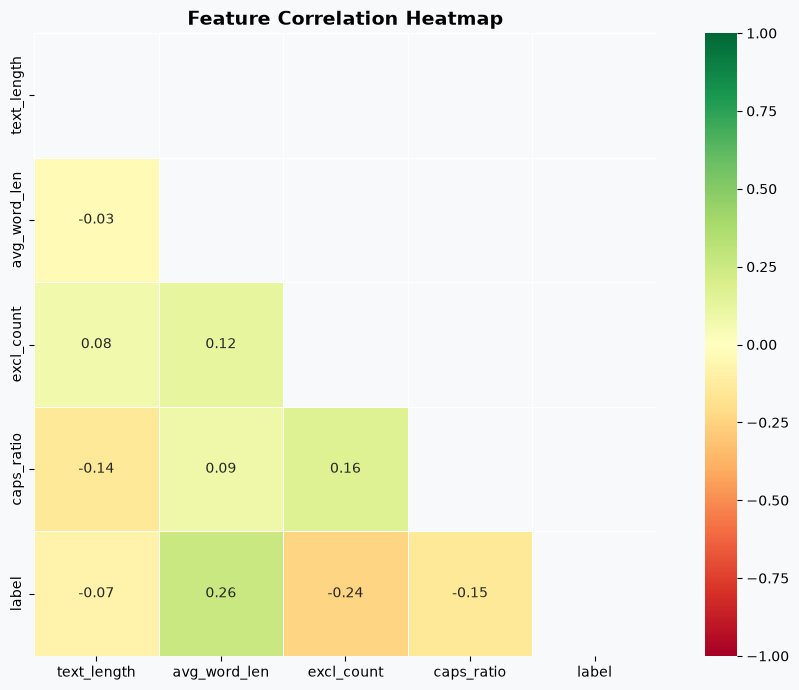

In [17]:
# --- Feature Correlation Heatmap ---

# Create figure
plt.figure(figsize=(10, 7))

# Correlation matrix
corr = df[num_cols].corr()

# Mask upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Draw heatmap
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

# Title
plt.title(
    'Feature Correlation Heatmap',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Phase 5 — Train / Val / Test Split (70 / 10 / 20)

In [18]:
# ── Features & Labels ────────────────────────────────────────────────────────
X = df['text_clean']
y = df['label']

SEED = 42

# ── Step 1: Split into Train (70%) and Temporary Set (30%) ──────────────────
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# ── Step 2: Split Temporary Set into Validation (10%) and Test (20%) ───────
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=2/3,
    random_state=SEED,
    stratify=y_temp
)

# ── Display Dataset Sizes ────────────────────────────────────────────────────
print(f"Train size      : {len(X_train):,} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation size : {len(X_val):,} ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test size       : {len(X_test):,} ({len(X_test)/len(X)*100:.1f}%)")

# ── Check Class Distribution ────────────────────────────────────────────────
print("\nTrain Class Distribution:")
print(y_train.value_counts())

print("\nValidation Class Distribution:")
print(y_val.value_counts())

print("\nTest Class Distribution:")
print(y_test.value_counts())

Train size      : 26,752 (70.0%)
Validation size : 3,822 (10.0%)
Test size       : 7,644 (20.0%)

Train Class Distribution:
label
1    14646
0    12106
Name: count, dtype: int64

Validation Class Distribution:
label
1    2092
0    1730
Name: count, dtype: int64

Test Class Distribution:
label
1    4185
0    3459
Name: count, dtype: int64


## Phase 6 — Baseline TF-IDF

In [19]:
# Fit TF-IDF on training data ONLY — avoids data leakage
TFIDF = TfidfVectorizer(max_features=100_000, ngram_range=(1, 2),
                         sublinear_tf=True, min_df=3)
X_tr_tf = TFIDF.fit_transform(X_train)
X_vl_tf = TFIDF.transform(X_val)
X_te_tf = TFIDF.transform(X_test)
print(f"TF-IDF matrix shape (train): {X_tr_tf.shape}")


TF-IDF matrix shape (train): (26752, 100000)


### 6.1 Baseline Model Training


In [20]:
# Train the 4 classical baselines on the TF-IDF features and score them on the held-out test set
baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Multinomial NB': MultinomialNB()
}

baseline_results = {}
print("Training baseline TF-IDF models...")
for name, clf in baseline_models.items():
    clf.fit(X_tr_tf, y_train)
    preds = clf.predict(X_te_tf)
    probs = clf.predict_proba(X_te_tf)[:, 1]
    baseline_results[name] = {
        'Accuracy' : accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall'   : recall_score(y_test, preds),
        'F1'       : f1_score(y_test, preds),
        'AUC'      : roc_auc_score(y_test, probs),
    }
    print(f"  {name:<20}: Acc={baseline_results[name]['Accuracy']:.4f}  F1={baseline_results[name]['F1']:.4f}")

print("\nBaseline models trained.")


Training baseline TF-IDF models...
  Logistic Regression : Acc=0.9830  F1=0.9846
  Random Forest       : Acc=0.9793  F1=0.9813
  Gradient Boosting   : Acc=0.9804  F1=0.9822
  Multinomial NB      : Acc=0.9545  F1=0.9586

Baseline models trained.


## Phase 7 — Deep Learning Models

##7.1 Tokenization and Padding

In [21]:
MAX_WORDS       = 50_000
MAX_LEN         = 400
EMBED_DIM   = 128 # Renamed from EMBED_DIM
BATCH_SIZE      = 64
EPOCHS          = 10

# Derived image dimensions for 2D CNN
IMG_H           = MAX_LEN  # Height of the "image" (time steps)
IMG_W           = EMBED_DIM  # Width of the "image" (embedding dimensions)
IMG_C           = 1        # Number of channels for the "image"
SQUARE_RESHAPE  = False    # Use tall grayscale image by default
LR_INIT         = 1e-3     # Initial learning rate


class SimpleTokenizer:
    """
    PyTorch-compatible stand-in for keras.preprocessing.text.Tokenizer:
    same word_index / texts_to_sequences interface, no TensorFlow dependency.
    Text is already lowercased/cleaned by Phase 4, so a plain whitespace
    split reproduces Keras' default tokenization here.
    """
    def __init__(self, num_words=None, oov_token=None):
        self.num_words = num_words
        self.oov_token = oov_token
        self.word_index = {}
        self.word_counts = Counter()

    def fit_on_texts(self, texts):
        for text in texts:
            self.word_counts.update(str(text).split())

        # Reserve index 1 for the OOV token; assign remaining indices by frequency
        idx = 1
        if self.oov_token is not None:
            self.word_index[self.oov_token] = idx
            idx += 1
        for word, _ in self.word_counts.most_common():
            self.word_index[word] = idx
            idx += 1

    def texts_to_sequences(self, texts):
        oov_idx = self.word_index.get(self.oov_token) if self.oov_token else None
        sequences = []
        for text in texts:
            seq = []
            for word in str(text).split():
                word_idx = self.word_index.get(word)
                if word_idx is not None and (self.num_words is None or word_idx < self.num_words):
                    seq.append(word_idx)
                elif oov_idx is not None:
                    seq.append(oov_idx)
            sequences.append(seq)
        return sequences


def pad_sequences(sequences, maxlen=None, padding='post', truncating='post', value=0):
    """PyTorch-compatible stand-in for keras.preprocessing.sequence.pad_sequences."""
    if maxlen is None:
        maxlen = max((len(s) for s in sequences), default=0)
    padded = np.full((len(sequences), maxlen), value, dtype='int32')
    for i, seq in enumerate(sequences):
        if len(seq) == 0:
            continue
        trunc = seq[-maxlen:] if truncating == 'pre' else seq[:maxlen]
        if padding == 'post':
            padded[i, :len(trunc)] = trunc
        else:
            padded[i, -len(trunc):] = trunc
    return padded


# Fit tokenizer on training data ONLY — avoids data leakage
tokenizer = SimpleTokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

def encode(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')

X_tr_seq = encode(X_train)
X_vl_seq = encode(X_val)
X_te_seq = encode(X_test)

print(f'Vocab size : {len(tokenizer.word_index):,}')
print(f'Train shape: {X_tr_seq.shape}')


Vocab size : 316,575
Train shape: (26752, 400)


----------------------------------------

### 7.2 Shared Callbacks (EarlyStopping at 98.5%, Epochs=10, Batch=64)

In [22]:
# ============================================================
# Shared PyTorch Infrastructure: Device, Callbacks, Model Wrappers
# ============================================================
import copy
from types import SimpleNamespace

# ── Device selection (GPU with graceful CPU fallback) ──────────────────────
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    print(f'GPU detected: {torch.cuda.get_device_name(0)} — training will run on GPU.')
else:
    print('No GPU detected — falling back to CPU. Training will be slower.')

os.makedirs('weights', exist_ok=True)


def softmax_np(logits, axis=-1):
    """NumPy softmax — replacement for tf.nn.softmax(...).numpy()."""
    logits = np.asarray(logits, dtype=np.float64)
    shifted = logits - np.max(logits, axis=axis, keepdims=True)
    exp = np.exp(shifted)
    return (exp / np.sum(exp, axis=axis, keepdims=True)).astype(np.float32)


class SpatialDropout1D(nn.Module):
    """Drops entire embedding channels across all timesteps (matches Keras SpatialDropout1D)."""
    def __init__(self, p):
        super().__init__()
        self.p = p

    def forward(self, x):  # x: (batch, time, channels)
        if not self.training or self.p == 0:
            return x
        mask = x.new_empty(x.size(0), 1, x.size(2)).bernoulli_(1 - self.p) / (1 - self.p)
        return x * mask


class History:
    """Mimics Keras' History object so downstream plotting cells stay unchanged."""
    def __init__(self):
        self.history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}


# ── Torch-native callbacks (drop-in replacements for tf.keras.callbacks) ───
class Callback:
    def on_epoch_end(self, epoch, logs, model, optimizer):
        pass

    def should_stop(self):
        return False


class AccuracyThreshold(Callback):
    """Stop training when val_accuracy reaches 98.5%."""
    def __init__(self, threshold=0.985):
        self.threshold = threshold
        self._stop = False

    def on_epoch_end(self, epoch, logs, model, optimizer):
        if logs.get('val_accuracy', 0) >= self.threshold:
            print(f"\nReached {self.threshold*100:.1f}% val_accuracy at epoch {epoch+1} — stopping early.")
            self._stop = True

    def should_stop(self):
        return self._stop


class EarlyStopping(Callback):
    def __init__(self, monitor='val_loss', mode='min', patience=3, min_delta=0.0,
                 restore_best_weights=True, verbose=0):
        self.monitor = monitor
        self.mode = mode
        self.patience = patience
        self.min_delta = min_delta
        self.restore_best_weights = restore_best_weights
        self.verbose = verbose
        self.best = np.inf if mode == 'min' else -np.inf
        self.wait = 0
        self.best_state = None
        self._stop = False

    def _is_improvement(self, current):
        if self.mode == 'min':
            return current < self.best - self.min_delta
        return current > self.best + self.min_delta

    def on_epoch_end(self, epoch, logs, model, optimizer):
        current = logs.get(self.monitor)
        if current is None:
            return
        if self._is_improvement(current):
            self.best = current
            self.wait = 0
            if self.restore_best_weights:
                self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self._stop = True
                if self.verbose:
                    print(f"\nEarlyStopping: no improvement in {self.monitor} for {self.patience} "
                          f"epochs — stopping at epoch {epoch+1}.")
                if self.restore_best_weights and self.best_state is not None:
                    model.load_state_dict(self.best_state)

    def should_stop(self):
        return self._stop


class ReduceLROnPlateau(Callback):
    def __init__(self, monitor='val_loss', mode='min', factor=0.3, patience=2,
                 min_lr=1e-6, verbose=0):
        self.monitor = monitor
        self.mode = mode
        self.factor = factor
        self.patience = patience
        self.min_lr = min_lr
        self.verbose = verbose
        self.best = np.inf if mode == 'min' else -np.inf
        self.wait = 0

    def on_epoch_end(self, epoch, logs, model, optimizer):
        current = logs.get(self.monitor)
        if current is None:
            return
        improved = current < self.best if self.mode == 'min' else current > self.best
        if improved:
            self.best = current
            self.wait = 0
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.wait = 0
                for group in optimizer.param_groups:
                    new_lr = max(group['lr'] * self.factor, self.min_lr)
                    if self.verbose and new_lr < group['lr']:
                        print(f"\nReduceLROnPlateau: reducing learning rate to {new_lr:.2e}.")
                    group['lr'] = new_lr

    def should_stop(self):
        return False


class ModelCheckpoint(Callback):
    """Saves model weights with torch.save (.pt) — native PyTorch checkpoint format."""
    def __init__(self, filepath, monitor='val_loss', mode='min', save_best_only=True,
                 save_weights_only=True, save_freq='epoch', verbose=0):
        self.filepath = filepath
        self.monitor = monitor
        self.mode = mode
        self.save_best_only = save_best_only
        self.verbose = verbose
        self.best = np.inf if mode == 'min' else -np.inf

    def on_epoch_end(self, epoch, logs, model, optimizer):
        path = self.filepath.format(epoch=epoch + 1)
        if self.save_best_only:
            current = logs.get(self.monitor)
            if current is None:
                return
            improved = current < self.best if self.mode == 'min' else current > self.best
            if not improved:
                return
            self.best = current
        os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
        torch.save(model.state_dict(), path)
        if self.verbose:
            print(f"\nModelCheckpoint: saved weights to {path}")

    def should_stop(self):
        return False


def get_callbacks(model_name):
    os.makedirs('weights', exist_ok=True)
    return [
        AccuracyThreshold(),

        # 1. Monitored val_loss in 'min' mode to dynamically detect overfitting
        EarlyStopping(monitor='val_loss', mode='min', patience=3,
                      restore_best_weights=True, verbose=1),

        # 2. Reduces learning rate when val_loss plateaus to hit the global minimum
        ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.3, patience=2,
                          min_lr=1e-6, verbose=1),

        # 3. Saves the best model weights based on the lowest validation loss (native .pt format)
        ModelCheckpoint(f'best_{model_name}.pt', monitor='val_loss', mode='min',
                        save_best_only=True, verbose=0),

        # 4. Saves model weights after EVERY epoch
        ModelCheckpoint('weights/' + model_name + '_epoch_{epoch:02d}.pt',
                        save_weights_only=True, save_freq='epoch', verbose=1),
    ]


# ── Keras-like wrapper around a binary-sigmoid PyTorch nn.Module ───────────
class TorchSeqModel:
    """
    Wraps a torch.nn.Module that outputs raw logits for binary classification,
    exposing a Keras-style .summary()/.fit()/.predict()/.evaluate() API so the
    surrounding training/evaluation/plotting cells stay unchanged after the
    TensorFlow -> PyTorch migration.
    """
    def __init__(self, net, name='model', lr=1e-3, weight_decay=0.0):
        self.net = net.to(DEVICE)
        self.name = name
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=lr, weight_decay=weight_decay)
        self.criterion = nn.BCEWithLogitsLoss()

    def summary(self):
        print(self.net)
        n_params = sum(p.numel() for p in self.net.parameters())
        print(f"Total params: {n_params:,}")

    def _loader(self, X, y, batch_size, shuffle):
        X_t = torch.as_tensor(np.asarray(X), dtype=torch.long)
        y_t = torch.as_tensor(np.asarray(y), dtype=torch.float32)
        ds = TensorDataset(X_t, y_t)
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

    def _run_epoch(self, loader, train):
        self.net.train(train)
        total_loss, total_correct, total_n = 0.0, 0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            with torch.set_grad_enabled(train):
                logits = self.net(xb)
                loss = self.criterion(logits, yb)
                if train:
                    self.optimizer.zero_grad()
                    loss.backward()
                    self.optimizer.step()
            probs = torch.sigmoid(logits)
            total_loss += loss.item() * xb.size(0)
            total_correct += ((probs >= 0.5).float() == yb).sum().item()
            total_n += xb.size(0)
        return total_loss / total_n, total_correct / total_n

    def fit(self, X, y, epochs=10, batch_size=64, validation_data=None,
            callbacks=None, verbose=1):
        callbacks = callbacks or []
        train_loader = self._loader(X, y, batch_size, shuffle=True)
        val_loader = None
        if validation_data is not None:
            X_val, y_val = validation_data
            val_loader = self._loader(X_val, y_val, batch_size, shuffle=False)

        history = History()
        for epoch in range(epochs):
            train_loss, train_acc = self._run_epoch(train_loader, train=True)
            logs = {'loss': train_loss, 'accuracy': train_acc}
            if val_loader is not None:
                val_loss, val_acc = self._run_epoch(val_loader, train=False)
                logs['val_loss'], logs['val_accuracy'] = val_loss, val_acc

            for k, v in logs.items():
                history.history[k].append(v)

            if verbose:
                msg = f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f}"
                if val_loader is not None:
                    msg += f" - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}"
                print(msg)

            for cb in callbacks:
                cb.on_epoch_end(epoch, logs, self.net, self.optimizer)
            if any(cb.should_stop() for cb in callbacks):
                break

        return history

    @torch.no_grad()
    def predict(self, X, batch_size=64, verbose=0):
        self.net.eval()
        X_t = torch.as_tensor(np.asarray(X), dtype=torch.long)
        outputs = []
        for i in range(0, len(X_t), batch_size):
            xb = X_t[i:i + batch_size].to(DEVICE)
            outputs.append(torch.sigmoid(self.net(xb)).cpu().numpy())
        return np.concatenate(outputs).reshape(-1, 1)

    def evaluate(self, X, y, batch_size=64, verbose=0):
        loader = self._loader(X, y, batch_size, shuffle=False)
        return self._run_epoch(loader, train=False)


# ── Keras-like wrapper around a HuggingFace PyTorch sequence-classifier ────
class TorchBertClassifier:
    """
    Wraps a HuggingFace *AutoModelForSequenceClassification* (pure PyTorch),
    exposing .fit()/.predict()/.evaluate()/__call__ so cells written against
    the old TFAutoModelForSequenceClassification API keep working unchanged.
    """
    def __init__(self, model, lr=2e-5, total_steps=None, warmup_ratio=0.1, weight_decay=0.01):
        self.model = model.to(DEVICE)
        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=lr, weight_decay=weight_decay)
        self.scheduler = None
        if total_steps:
            from transformers import get_linear_schedule_with_warmup
            self.scheduler = get_linear_schedule_with_warmup(
                self.optimizer,
                num_warmup_steps=int(warmup_ratio * total_steps),
                num_training_steps=total_steps
            )

    @staticmethod
    def _unpack(inputs):
        """Normalises list/tuple/dict/BatchEncoding input into (ids, mask) tensors."""
        if isinstance(inputs, dict) or hasattr(inputs, 'keys'):
            ids, mask = inputs['input_ids'], inputs['attention_mask']
        else:
            ids, mask = inputs[0], inputs[1]
        ids = ids.long() if torch.is_tensor(ids) else torch.as_tensor(np.asarray(ids), dtype=torch.long)
        mask = mask.long() if torch.is_tensor(mask) else torch.as_tensor(np.asarray(mask), dtype=torch.long)
        return ids, mask

    def _loader(self, inputs, y, batch_size, shuffle):
        ids, mask = self._unpack(inputs)
        y_t = torch.as_tensor(np.asarray(y), dtype=torch.long)
        ds = TensorDataset(ids, mask, y_t)
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

    def _run_epoch(self, loader, train):
        self.model.train(train)
        total_loss, total_correct, total_n = 0.0, 0, 0
        for ids, mask, yb in loader:
            ids, mask, yb = ids.to(DEVICE), mask.to(DEVICE), yb.to(DEVICE)
            with torch.set_grad_enabled(train):
                out = self.model(input_ids=ids, attention_mask=mask, labels=yb)
                loss = out.loss
                if train:
                    self.optimizer.zero_grad()
                    loss.backward()
                    self.optimizer.step()
                    if self.scheduler:
                        self.scheduler.step()
            total_loss += loss.item() * ids.size(0)
            total_correct += (out.logits.argmax(dim=-1) == yb).sum().item()
            total_n += ids.size(0)
        return total_loss / total_n, total_correct / total_n

    def fit(self, inputs, y, epochs=3, batch_size=16, validation_data=None,
            callbacks=None, verbose=1):
        callbacks = callbacks or []
        train_loader = self._loader(inputs, y, batch_size, shuffle=True)
        val_loader = None
        if validation_data is not None:
            val_inputs, y_val = validation_data
            val_loader = self._loader(val_inputs, y_val, batch_size, shuffle=False)

        history = History()
        for epoch in range(epochs):
            train_loss, train_acc = self._run_epoch(train_loader, train=True)
            logs = {'loss': train_loss, 'accuracy': train_acc}
            if val_loader is not None:
                val_loss, val_acc = self._run_epoch(val_loader, train=False)
                logs['val_loss'], logs['val_accuracy'] = val_loss, val_acc

            for k, v in logs.items():
                history.history[k].append(v)

            if verbose:
                msg = f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f}"
                if val_loader is not None:
                    msg += f" - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}"
                print(msg)

            for cb in callbacks:
                cb.on_epoch_end(epoch, logs, self.model, self.optimizer)
            if any(cb.should_stop() for cb in callbacks):
                break

        return history

    @torch.no_grad()
    def predict(self, inputs, batch_size=32, verbose=0):
        self.model.eval()
        ids, mask = self._unpack(inputs)
        logits_list = []
        for i in range(0, len(ids), batch_size):
            b_ids = ids[i:i + batch_size].to(DEVICE)
            b_mask = mask[i:i + batch_size].to(DEVICE)
            out = self.model(input_ids=b_ids, attention_mask=b_mask)
            logits_list.append(out.logits.cpu().numpy())
        return SimpleNamespace(logits=np.concatenate(logits_list, axis=0))

    def evaluate(self, inputs, y, batch_size=32, verbose=0):
        loader = self._loader(inputs, y, batch_size, shuffle=False)
        return self._run_epoch(loader, train=False)

    def __call__(self, inputs, training=False):
        """Mirrors calling the old TF model directly — used by the SHAP wrappers."""
        was_training = self.model.training
        self.model.train(training)
        ids, mask = self._unpack(inputs)
        ids, mask = ids.to(DEVICE), mask.to(DEVICE)
        if training:
            out = self.model(input_ids=ids, attention_mask=mask)
        else:
            with torch.no_grad():
                out = self.model(input_ids=ids, attention_mask=mask)
        self.model.train(was_training)
        return SimpleNamespace(logits=out.logits.detach().cpu().numpy())


dl_results = {}
print("Callbacks ready and optimized.")


GPU detected: NVIDIA RTX 2000 Ada Generation — training will run on GPU.
Callbacks ready and optimized.




# Model 1 : BiLSTM 1



In [23]:
#  Fix Random Seed for Reproducibility (Model 1: BiLSTM)
SEED = 42
import os, random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


In [24]:
class LSTMNet(nn.Module):
    """Embedding -> stacked BiLSTM -> Dense head (PyTorch port of the original Keras LSTM model)."""
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(MAX_WORDS, EMBED_DIM, padding_idx=0)
        self.spatial_dropout = SpatialDropout1D(0.5)
        self.lstm1 = nn.LSTM(EMBED_DIM, 128, batch_first=True, bidirectional=True)
        self.lstm2 = nn.LSTM(256, 64, batch_first=True, bidirectional=True)
        self.fc1 = nn.Linear(128, 64)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        emb = self.spatial_dropout(self.embedding(x))
        out, _ = self.lstm1(emb)
        _, (h_n, _) = self.lstm2(out)
        # Concatenate the final forward/backward hidden states — the PyTorch
        # equivalent of Keras' Bidirectional(LSTM(64)) without return_sequences.
        h = torch.cat([h_n[0], h_n[1]], dim=1)
        x = F.relu(self.fc1(h))
        x = self.dropout(x)
        return self.fc2(x).squeeze(-1)  # raw logits; sigmoid applied inside the wrapper


def build_lstm():
    return TorchSeqModel(LSTMNet(), name='BiLSTM', lr=1e-3)

# Instantiate and verify the model instantly
lstm_model = build_lstm()
lstm_model.summary()


LSTMNet(
  (embedding): Embedding(50000, 128, padding_idx=0)
  (spatial_dropout): SpatialDropout1D()
  (lstm1): LSTM(128, 128, batch_first=True, bidirectional=True)
  (lstm2): LSTM(256, 64, batch_first=True, bidirectional=True)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)
Total params: 6,837,377


Training BiLSTM Model...
Epoch 1/10 - loss: 0.2965 - accuracy: 0.8736 - val_loss: 0.1507 - val_accuracy: 0.9490

ModelCheckpoint: saved weights to weights/lstm_epoch_01.pt
Epoch 2/10 - loss: 0.1218 - accuracy: 0.9563 - val_loss: 0.0979 - val_accuracy: 0.9639

ModelCheckpoint: saved weights to weights/lstm_epoch_02.pt
Epoch 3/10 - loss: 0.0591 - accuracy: 0.9811 - val_loss: 0.0357 - val_accuracy: 0.9867

ModelCheckpoint: saved weights to weights/lstm_epoch_03.pt
Epoch 4/10 - loss: 0.0373 - accuracy: 0.9876 - val_loss: 0.0262 - val_accuracy: 0.9901

ModelCheckpoint: saved weights to weights/lstm_epoch_04.pt

Model A: LSTM Performance Summary Table:


,Dataset Split,Accuracy,Loss
0,Training Set,0.9876,0.0373
1,Validation Set,0.9901,0.0262
2,Testing Set,0.9432,0.1589



Classification Report (Test Set):

              precision    recall  f1-score   support

   Fake News       0.93      0.95      0.94      3459
   Real News       0.96      0.94      0.95      4185

    accuracy                           0.94      7644
   macro avg       0.94      0.94      0.94      7644
weighted avg       0.94      0.94      0.94      7644



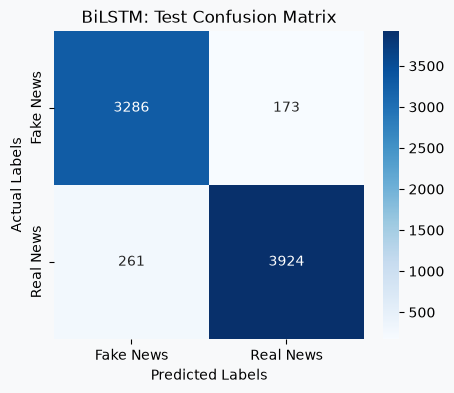

In [25]:
from nltk import metrics
# 1. Training with Callbacks
os.makedirs('weights', exist_ok=True)
callbacks = [
    EarlyStopping(monitor='val_loss',min_delta=0.2, patience=3, restore_best_weights=True),
    # Save model weights after EVERY epoch (native PyTorch checkpoint format)
    ModelCheckpoint('weights/lstm_epoch_{epoch:02d}.pt', save_weights_only=True, save_freq='epoch', verbose=1)
]

print("Training BiLSTM Model...")
history = lstm_model.fit(
    X_tr_seq, y_train, epochs=10, batch_size=64,
    validation_data=(X_vl_seq, y_val), callbacks=callbacks, verbose=1
)

# 2. Extract metrics at best epoch
best_idx = history.history['val_loss'].index(min(history.history['val_loss']))
train_acc = history.history['accuracy'][best_idx]
train_loss = history.history['loss'][best_idx]
val_acc = history.history['val_accuracy'][best_idx]
val_loss = history.history['val_loss'][best_idx]

# 3. Evaluate Test Data
test_loss, test_acc = lstm_model.evaluate(X_te_seq, y_test, verbose=0)

# 4. Display Performance Table
print("\nModel A: LSTM Performance Summary Table:")
df_metrics = pd.DataFrame({
    "Dataset Split": ["Training Set", "Validation Set", "Testing Set"],
    "Accuracy": [f"{train_acc:.4f}", f"{val_acc:.4f}", f"{test_acc:.4f}"],
    "Loss": [f"{train_loss:.4f}", f"{val_loss:.4f}", f"{test_loss:.4f}"]
})
display(df_metrics)

# 5. Generate Confusion Matrix
y_pred = (lstm_model.predict(X_te_seq, verbose=0) >= 0.5).astype(int)

print("\nClassification Report (Test Set):\n")
print(classification_report(y_test, y_pred, target_names=['Fake News', 'Real News']))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake News', 'Real News'], yticklabels=['Fake News', 'Real News'])
plt.title('BiLSTM: Test Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.show()


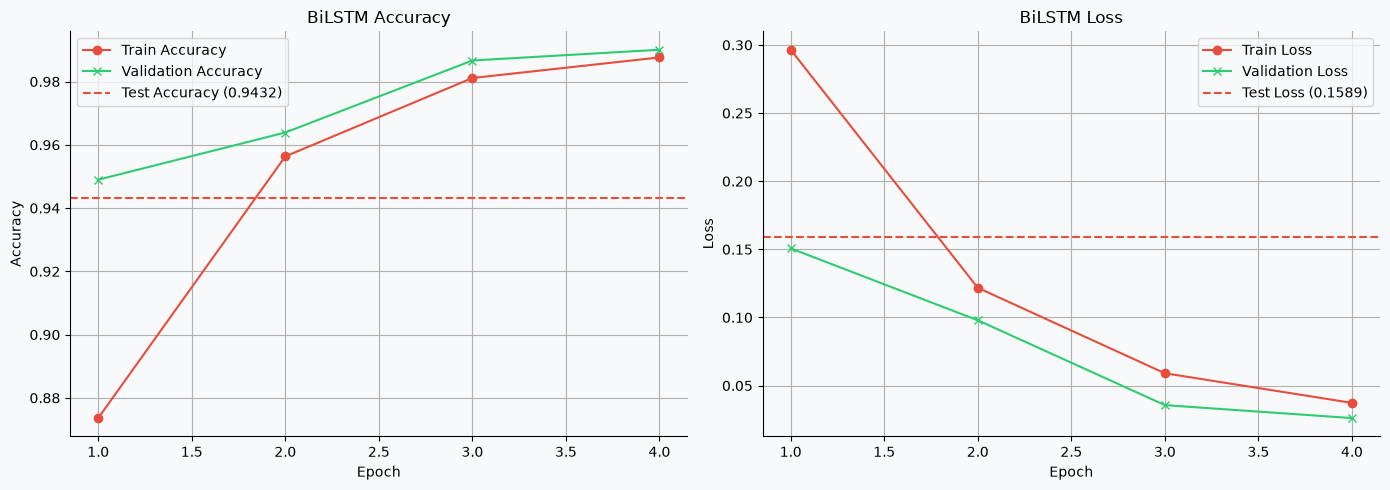

In [26]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history.history['accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Accuracy
axes[0].plot(
    epochs_range,
    history.history['accuracy'],
    marker='o',
    label='Train Accuracy'
)

axes[0].plot(
    epochs_range,
    history.history['val_accuracy'],
    marker='x',
    label='Validation Accuracy'
)

axes[0].axhline(
    y=test_acc,
    linestyle='--',
    label=f'Test Accuracy ({test_acc:.4f})'
)

axes[0].set_title("BiLSTM Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(
    epochs_range,
    history.history['loss'],
    marker='o',
    label='Train Loss'
)

axes[1].plot(
    epochs_range,
    history.history['val_loss'],
    marker='x',
    label='Validation Loss'
)

axes[1].axhline(
    y=test_loss,
    linestyle='--',
    label=f'Test Loss ({test_loss:.4f})'
)

axes[1].set_title("BiLSTM Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### 7.3 Model 2 — BiLSTM + Attention

In [27]:
#  Fix Random Seed for Reproducibility (Model 2: BiLSTM + Attention)
SEED = 42
import os, random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


In [28]:
print(MAX_WORDS)
print(MAX_LEN)
print(EMBED_DIM)

50000
400
128


In [29]:
# Free up GPU memory before building
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

class BiLSTMAttentionNet(nn.Module):
    """Embedding -> stacked BiLSTM -> Multi-Head Self-Attention (+residual) -> Dense head."""
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(MAX_WORDS, EMBED_DIM, padding_idx=0)
        self.spatial_dropout = SpatialDropout1D(0.4)
        # nn.LSTM's dropout/recurrent_dropout only apply between stacked layers;
        # these are single-layer LSTMs, so SpatialDropout1D + the Dense-head
        # Dropout layers below carry the regularization instead (documented
        # minimal deviation from Keras' per-cell recurrent_dropout).
        self.lstm1 = nn.LSTM(EMBED_DIM, 64, batch_first=True, bidirectional=True)
        self.bn = nn.BatchNorm1d(128)
        self.lstm2 = nn.LSTM(128, 32, batch_first=True, bidirectional=True)
        self.attn = nn.MultiheadAttention(embed_dim=64, num_heads=4, batch_first=True)
        self.ln = nn.LayerNorm(64)
        self.fc1 = nn.Linear(64, 128)
        self.drop1 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 64)
        self.drop2 = nn.Dropout(0.3)
        self.fc3 = nn.Linear(64, 1)

    def forward(self, x):
        emb = self.spatial_dropout(self.embedding(x))
        out, _ = self.lstm1(emb)
        out = self.bn(out.transpose(1, 2)).transpose(1, 2)
        out, _ = self.lstm2(out)

        # Multi-Head Self-Attention + residual connection
        attn_out, _ = self.attn(out, out, out)
        x = self.ln(out + attn_out)

        x = x.mean(dim=1)  # GlobalAveragePooling1D
        x = F.relu(self.fc1(x))
        x = self.drop1(x)
        x = F.relu(self.fc2(x))
        x = self.drop2(x)
        return self.fc3(x).squeeze(-1)


def build_bilstm_attention():
    # weight_decay approximates the original Keras l2(1e-4) kernel regularizers
    return TorchSeqModel(BiLSTMAttentionNet(), name='bilstm_attention', lr=3e-4, weight_decay=1e-4)

# Using bilstm_model as requested
bilstm_model = build_bilstm_attention()
bilstm_model.summary()


BiLSTMAttentionNet(
  (embedding): Embedding(50000, 128, padding_idx=0)
  (spatial_dropout): SpatialDropout1D()
  (lstm1): LSTM(128, 64, batch_first=True, bidirectional=True)
  (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (lstm2): LSTM(128, 32, batch_first=True, bidirectional=True)
  (attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
  )
  (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (fc1): Linear(in_features=64, out_features=128, bias=True)
  (drop1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (drop2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=64, out_features=1, bias=True)
)
Total params: 6,574,465


In [30]:
import json

In [31]:
print("Training BiLSTM + Attention Model using your custom callbacks...")
# Calling your existing function directly without re-defining it
history_att = bilstm_model.fit(
    X_tr_seq, y_train, epochs=10, batch_size=64,
    validation_data=(X_vl_seq, y_val),
    callbacks=get_callbacks('bilstm_attention'),
    verbose=1
)

# Extract precise metrics at the best epoch (restored weights)
best_idx = history_att.history['val_loss'].index(min(history_att.history['val_loss']))
train_acc = history_att.history['accuracy'][best_idx]
train_loss = history_att.history['loss'][best_idx]
val_acc = history_att.history['val_accuracy'][best_idx]
val_loss = history_att.history['val_loss'][best_idx]

# Evaluate Test Data independently
test_loss, test_acc = bilstm_model.evaluate(X_te_seq, y_test, verbose=1)

# Save history to disk (Model file is already handled by your ModelCheckpoint)
print("\nSaving training history...")
with open('attention_history.json', 'w') as f:
    json.dump(history_att.history, f)
print("History saved successfully!")

Training BiLSTM + Attention Model using your custom callbacks...
Epoch 1/10 - loss: 0.3295 - accuracy: 0.8470 - val_loss: 0.1034 - val_accuracy: 0.9623

ModelCheckpoint: saved weights to weights/bilstm_attention_epoch_01.pt
Epoch 2/10 - loss: 0.1143 - accuracy: 0.9593 - val_loss: 0.0690 - val_accuracy: 0.9749

ModelCheckpoint: saved weights to weights/bilstm_attention_epoch_02.pt
Epoch 3/10 - loss: 0.0824 - accuracy: 0.9694 - val_loss: 0.0497 - val_accuracy: 0.9833

ModelCheckpoint: saved weights to weights/bilstm_attention_epoch_03.pt
Epoch 4/10 - loss: 0.0657 - accuracy: 0.9766 - val_loss: 0.0422 - val_accuracy: 0.9872

Reached 98.5% val_accuracy at epoch 4 — stopping early.

ModelCheckpoint: saved weights to weights/bilstm_attention_epoch_04.pt

Saving training history...
History saved successfully!


Model 2: BiLSTM + Attention Performance Summary Table:


,Dataset Split,Accuracy,Loss
0,Training Set,0.9766,0.0657
1,Validation Set,0.9872,0.0422
2,Testing Set,0.9855,0.0433



Classification Report (Test Set):

              precision    recall  f1-score   support

   Fake News       0.98      0.99      0.98      3459
   Real News       0.99      0.99      0.99      4185

    accuracy                           0.99      7644
   macro avg       0.99      0.99      0.99      7644
weighted avg       0.99      0.99      0.99      7644



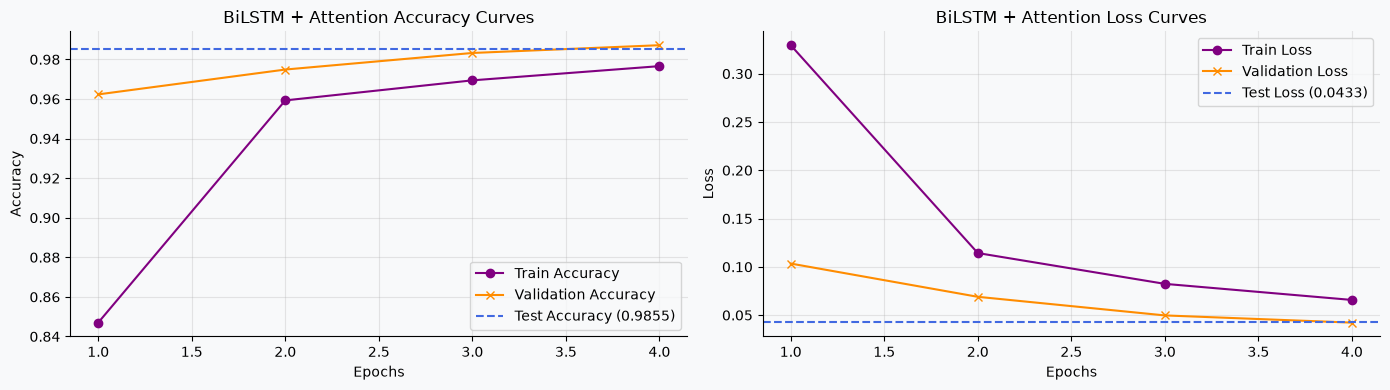


Generating Final Confusion Matrix Visual...


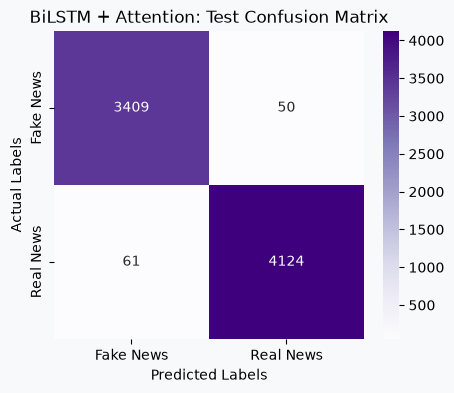

In [32]:
# 1. Display Performance Summary Table
print("Model 2: BiLSTM + Attention Performance Summary Table:")
df_metrics = pd.DataFrame({
    "Dataset Split": ["Training Set", "Validation Set", "Testing Set"],
    "Accuracy": [f"{train_acc:.4f}", f"{val_acc:.4f}", f"{test_acc:.4f}"],
    "Loss": [f"{train_loss:.4f}", f"{val_loss:.4f}", f"{test_loss:.4f}"]
})
display(df_metrics)

# 2. Display Classification Report
y_pred = (bilstm_model.predict(X_te_seq, verbose=0) >= 0.5).astype(int)
print("\nClassification Report (Test Set):\n")
print(classification_report(y_test, y_pred, target_names=['Fake News', 'Real News']))

# 3. Plot Training Curves (Train vs Validation vs Test)
epochs_range = range(1, len(history_att.history['accuracy']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(epochs_range, history_att.history['accuracy'], label='Train Accuracy', marker='o', color='purple')
axes[0].plot(epochs_range, history_att.history['val_accuracy'], label='Validation Accuracy', marker='x', color='darkorange')
axes[0].axhline(test_acc, linestyle='--', color='royalblue', label=f'Test Accuracy ({test_acc:.4f})')
axes[0].set_title('BiLSTM + Attention Accuracy Curves')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history_att.history['loss'], label='Train Loss', marker='o', color='purple')
axes[1].plot(epochs_range, history_att.history['val_loss'], label='Validation Loss', marker='x', color='darkorange')
axes[1].axhline(test_loss, linestyle='--', color='royalblue', label=f'Test Loss ({test_loss:.4f})')
axes[1].set_title('BiLSTM + Attention Loss Curves')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Generate Confusion Matrix at the very end
print("\nGenerating Final Confusion Matrix Visual...")
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Purples',
            xticklabels=['Fake News', 'Real News'], yticklabels=['Fake News', 'Real News'])
plt.title('BiLSTM + Attention: Test Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.show()

### 7.4 Model 3 — CNN Text Classifier

In [33]:
#  Fix Random Seed for Reproducibility (Model 3: CNN Text Classifier)
SEED = 42
import os, random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


In [34]:
# Free up GPU memory before building CNN
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

class CNNTextClassifierNet(nn.Module):
    """Embedding -> Conv1D -> BatchNorm -> GlobalMaxPool -> Dense head."""
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(MAX_WORDS, EMBED_DIM, padding_idx=0)
        self.spatial_dropout = SpatialDropout1D(0.4)
        self.conv = nn.Conv1d(EMBED_DIM, 128, kernel_size=5, padding=2)  # padding=2 == Keras 'same' for kernel=5
        self.bn = nn.BatchNorm1d(128)
        self.fc1 = nn.Linear(128, 128)
        self.drop1 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 64)
        self.drop2 = nn.Dropout(0.3)
        self.fc3 = nn.Linear(64, 1)

    def forward(self, x):
        emb = self.spatial_dropout(self.embedding(x)).transpose(1, 2)  # (B, E, T) for Conv1d
        c = F.relu(self.conv(emb))
        c = self.bn(c)
        pooled = torch.amax(c, dim=2)  # GlobalMaxPooling1D
        x = F.relu(self.fc1(pooled))
        x = self.drop1(x)
        x = F.relu(self.fc2(x))
        x = self.drop2(x)
        return self.fc3(x).squeeze(-1)


def build_cnn_text_classifier():
    return TorchSeqModel(CNNTextClassifierNet(), name='cnn_text', lr=3e-4, weight_decay=1e-4)

# Using cnn_model variable
cnn_model = build_cnn_text_classifier()
cnn_model.summary()


CNNTextClassifierNet(
  (embedding): Embedding(50000, 128, padding_idx=0)
  (spatial_dropout): SpatialDropout1D()
  (conv): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (drop1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (drop2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=64, out_features=1, bias=True)
)
Total params: 6,507,137


In [35]:
import json

print("Training CNN Model using your custom callbacks...")
# Calling your existing function directly without re-defining it
history_cnn = cnn_model.fit(
    X_tr_seq, y_train, epochs=10, batch_size=64,
    validation_data=(X_vl_seq, y_val),
    callbacks=get_callbacks('cnn_text'),
    verbose=1
)

# Extract precise metrics at the best epoch (restored weights)
best_idx = history_cnn.history['val_loss'].index(min(history_cnn.history['val_loss']))
train_acc = history_cnn.history['accuracy'][best_idx]
train_loss = history_cnn.history['loss'][best_idx]
val_acc = history_cnn.history['val_accuracy'][best_idx]
val_loss = history_cnn.history['val_loss'][best_idx]

# Evaluate Test Data independently (Train - Val - Test Integration)
test_loss, test_acc = cnn_model.evaluate(X_te_seq, y_test, verbose=0)

# Save history to disk (Model file is already handled by your ModelCheckpoint)
print("\nSaving CNN training history...")
with open('cnn_history.json', 'w') as f:
    json.dump(history_cnn.history, f)
print("CNN History saved successfully!")

Training CNN Model using your custom callbacks...
Epoch 1/10 - loss: 0.4375 - accuracy: 0.7654 - val_loss: 0.1361 - val_accuracy: 0.9500

ModelCheckpoint: saved weights to weights/cnn_text_epoch_01.pt
Epoch 2/10 - loss: 0.1287 - accuracy: 0.9544 - val_loss: 0.0737 - val_accuracy: 0.9738

ModelCheckpoint: saved weights to weights/cnn_text_epoch_02.pt
Epoch 3/10 - loss: 0.0796 - accuracy: 0.9719 - val_loss: 0.0609 - val_accuracy: 0.9806

ModelCheckpoint: saved weights to weights/cnn_text_epoch_03.pt
Epoch 4/10 - loss: 0.0605 - accuracy: 0.9798 - val_loss: 0.0588 - val_accuracy: 0.9796

ModelCheckpoint: saved weights to weights/cnn_text_epoch_04.pt
Epoch 5/10 - loss: 0.0560 - accuracy: 0.9797 - val_loss: 0.0510 - val_accuracy: 0.9833

ModelCheckpoint: saved weights to weights/cnn_text_epoch_05.pt
Epoch 6/10 - loss: 0.0457 - accuracy: 0.9847 - val_loss: 0.0509 - val_accuracy: 0.9833

ModelCheckpoint: saved weights to weights/cnn_text_epoch_06.pt
Epoch 7/10 - loss: 0.0384 - accuracy: 0.9867

Model 3: CNN Performance Summary Table:


,Dataset Split,Accuracy,Loss
0,Training Set,0.9871,0.0361
1,Validation Set,0.9851,0.0477
2,Testing Set,0.9864,0.0369



Classification Report (Test Set):

              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.98      3459
   Real News       0.98      0.99      0.99      4185

    accuracy                           0.99      7644
   macro avg       0.99      0.99      0.99      7644
weighted avg       0.99      0.99      0.99      7644


[+] Classification Report — TRAINING SET:

              precision    recall  f1-score   support

   Fake News       1.00      0.99      1.00     12106
   Real News       0.99      1.00      1.00     14646

    accuracy                           1.00     26752
   macro avg       1.00      1.00      1.00     26752
weighted avg       1.00      1.00      1.00     26752

------------------------------------------------------------

[+] Classification Report — VALIDATION SET:

              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.98      1730
   Real News       0.98      0.99      0.99      2

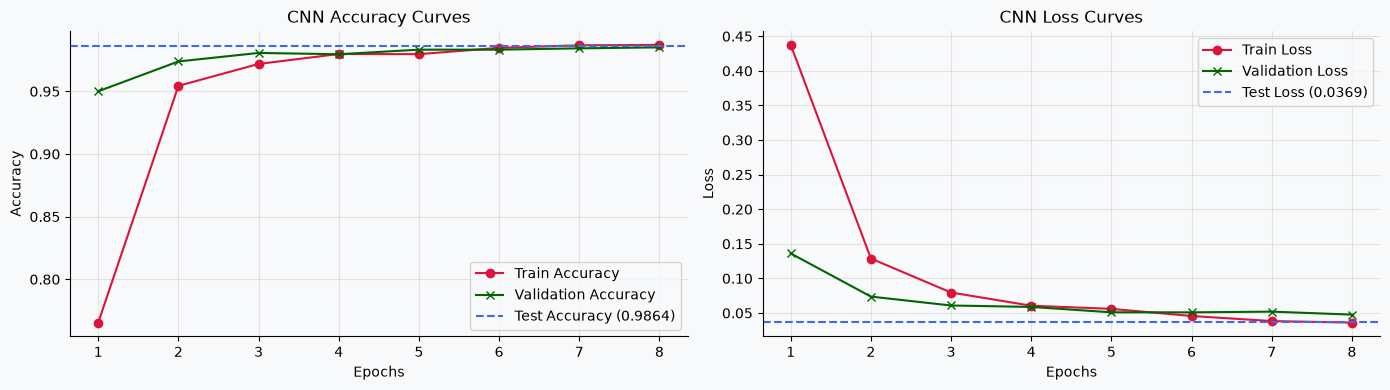


Generating Final Confusion Matrix Visual...


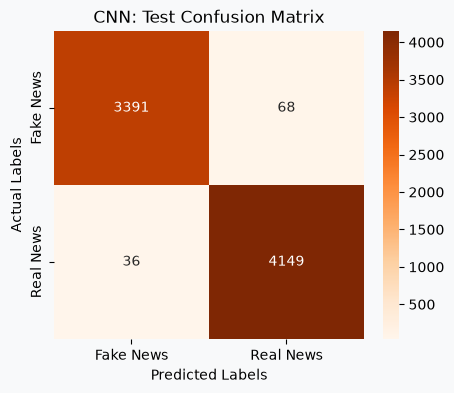

In [36]:
# 1. Display Performance Summary Table (Train - Validation - Test)
print("Model 3: CNN Performance Summary Table:")
df_metrics = pd.DataFrame({
    "Dataset Split": ["Training Set", "Validation Set", "Testing Set"],
    "Accuracy": [f"{train_acc:.4f}", f"{val_acc:.4f}", f"{test_acc:.4f}"],
    "Loss": [f"{train_loss:.4f}", f"{val_loss:.4f}", f"{test_loss:.4f}"]
})
display(df_metrics)

# 2. Display Classification Report for Test Set
y_pred = (cnn_model.predict(X_te_seq, verbose=0) >= 0.5).astype(int)
print("\nClassification Report (Test Set):\n")
print(classification_report(y_test, y_pred, target_names=['Fake News', 'Real News']))
splits = [("TRAINING SET", X_tr_seq, y_train),
          ("VALIDATION SET", X_vl_seq, y_val),
          ("TESTING SET", X_te_seq, y_test)]

for name, X_data, y_data in splits:
    y_pred = (cnn_model.predict(X_data, verbose=0) >= 0.5).astype(int)
    print(f"\n[+] Classification Report — {name}:\n")
    print(classification_report(y_data, y_pred, target_names=['Fake News', 'Real News']))
    print("-" * 60)
# 3. Plot Training Curves (Train vs Validation vs Test)
epochs_range = range(1, len(history_cnn.history['accuracy']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(epochs_range, history_cnn.history['accuracy'], label='Train Accuracy', marker='o', color='crimson')
axes[0].plot(epochs_range, history_cnn.history['val_accuracy'], label='Validation Accuracy', marker='x', color='darkgreen')
axes[0].axhline(test_acc, linestyle='--', color='royalblue', label=f'Test Accuracy ({test_acc:.4f})')
axes[0].set_title('CNN Accuracy Curves')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history_cnn.history['loss'], label='Train Loss', marker='o', color='crimson')
axes[1].plot(epochs_range, history_cnn.history['val_loss'], label='Validation Loss', marker='x', color='darkgreen')
axes[1].axhline(test_loss, linestyle='--', color='royalblue', label=f'Test Loss ({test_loss:.4f})')
axes[1].set_title('CNN Loss Curves')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Generate Final Confusion Matrix Visual at the very end
print("\nGenerating Final Confusion Matrix Visual...")
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Fake News', 'Real News'], yticklabels=['Fake News', 'Real News'])
plt.title('CNN: Test Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.show()

### 7.5 Model 4 — CNN-LSTM Hybrid

In [37]:
#  Fix Random Seed for Reproducibility (Model 4: CNN-LSTM Hybrid)
SEED = 42
import os, random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


In [38]:
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

class CNNLSTMHybridNet(nn.Module):
    """Multi-filter Conv1D branches -> BiLSTM -> Multi-Head Attention (+residual) -> dual global pooling -> Dense head."""
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(MAX_WORDS, EMBED_DIM, padding_idx=0)

        # 1. Multi-Filter CNN Block
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(EMBED_DIM, 128, kernel_size=fs, padding=fs // 2), nn.ReLU(),
                nn.Conv1d(128, 64, kernel_size=fs, padding=fs // 2), nn.ReLU(),
            )
            for fs in [3, 5, 7]
        ])
        merged_dim = 64 * len(self.branches)  # 192

        # 2. Bidirectional LSTM Block
        self.lstm = nn.LSTM(merged_dim, 128, batch_first=True, bidirectional=True)

        # 3. Multi-Head Attention Block
        self.attn = nn.MultiheadAttention(embed_dim=256, num_heads=4, batch_first=True)
        self.ln = nn.LayerNorm(256)

        # 5. Dense Classification Head
        self.fc1 = nn.Linear(256 * 2, 128)
        self.drop1 = nn.Dropout(0.40)
        self.fc2 = nn.Linear(128, 64)
        self.drop2 = nn.Dropout(0.30)
        self.fc3 = nn.Linear(64, 1)

    def forward(self, x):
        emb = self.embedding(x).transpose(1, 2)  # (B, E, T)
        merged = torch.cat([branch(emb) for branch in self.branches], dim=1).transpose(1, 2)  # (B, T, 192)

        lstm_out, _ = self.lstm(merged)
        attn_out, _ = self.attn(lstm_out, lstm_out, lstm_out)
        x = self.ln(lstm_out + attn_out)

        # 4. Global Pooling Block
        pooled = torch.cat([x.mean(dim=1), torch.amax(x, dim=1)], dim=1)

        x = self.drop1(F.relu(self.fc1(pooled)))
        x = self.drop2(F.relu(self.fc2(x)))
        return self.fc3(x).squeeze(-1)


def build_cnn_lstm():
    return TorchSeqModel(CNNLSTMHybridNet(), name='cnn_lstm_hybrid', lr=5e-4)

# Instantiate and show summary
cnn_lstm_model = build_cnn_lstm()
cnn_lstm_model.summary()


CNNLSTMHybridNet(
  (embedding): Embedding(50000, 128, padding_idx=0)
  (branches): ModuleList(
    (0): Sequential(
      (0): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): ReLU()
      (2): Conv1d(128, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (3): ReLU()
    )
    (1): Sequential(
      (0): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,))
      (1): ReLU()
      (2): Conv1d(128, 64, kernel_size=(5,), stride=(1,), padding=(2,))
      (3): ReLU()
    )
    (2): Sequential(
      (0): Conv1d(128, 128, kernel_size=(7,), stride=(1,), padding=(3,))
      (1): ReLU()
      (2): Conv1d(128, 64, kernel_size=(7,), stride=(1,), padding=(3,))
      (3): ReLU()
    )
  )
  (lstm): LSTM(192, 128, batch_first=True, bidirectional=True)
  (attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
  )
  (ln): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (fc1): Linear(in_feat

In [39]:
import time

print("Starting Training for Model 4: Advanced Hybrid Model...")

# 1. Callbacks with ModelCheckpoint to save the best model weights (native .pt format)
os.makedirs('weights', exist_ok=True)
callbacks_hybrid = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    ModelCheckpoint('best_cnn_lstm_hybrid.pt', monitor='val_loss', save_best_only=True, verbose=1),
    # Save model weights after EVERY epoch
    ModelCheckpoint('weights/cnn_lstm_hybrid_epoch_{epoch:02d}.pt',
                    save_weights_only=True, save_freq='epoch', verbose=1)
]

# 2. Train the model
start_time = time.time()

history_hybrid = cnn_lstm_model.fit(
    X_tr_seq, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_vl_seq, y_val),
    callbacks=callbacks_hybrid,
    verbose=1
)

hybrid_train_time = time.time() - start_time
print(f"\n✔ Training completed and model saved as 'best_cnn_lstm_hybrid.pt'!")
print(f"✔ Total Training Time: {hybrid_train_time:.2f} seconds.")


Starting Training for Model 4: Advanced Hybrid Model...
Epoch 1/10 - loss: 0.2270 - accuracy: 0.8775 - val_loss: 0.0487 - val_accuracy: 0.9819

ModelCheckpoint: saved weights to best_cnn_lstm_hybrid.pt

ModelCheckpoint: saved weights to weights/cnn_lstm_hybrid_epoch_01.pt
Epoch 2/10 - loss: 0.0372 - accuracy: 0.9884 - val_loss: 0.0331 - val_accuracy: 0.9885

ModelCheckpoint: saved weights to best_cnn_lstm_hybrid.pt

ModelCheckpoint: saved weights to weights/cnn_lstm_hybrid_epoch_02.pt
Epoch 3/10 - loss: 0.0143 - accuracy: 0.9957 - val_loss: 0.0318 - val_accuracy: 0.9885

ModelCheckpoint: saved weights to best_cnn_lstm_hybrid.pt

ModelCheckpoint: saved weights to weights/cnn_lstm_hybrid_epoch_03.pt
Epoch 4/10 - loss: 0.0106 - accuracy: 0.9970 - val_loss: 0.0306 - val_accuracy: 0.9903

ModelCheckpoint: saved weights to best_cnn_lstm_hybrid.pt

ModelCheckpoint: saved weights to weights/cnn_lstm_hybrid_epoch_04.pt
Epoch 5/10 - loss: 0.0049 - accuracy: 0.9986 - val_loss: 0.0416 - val_accura

Model 4: CNN-LSTM Hybrid Performance Summary Table:


,Dataset Split,Accuracy,Loss
0,Training Set,0.9994,0.0017
1,Validation Set,0.9908,0.0372
2,Testing Set,0.9922,0.0330



[+] Classification Report — TRAINING SET:

              precision    recall  f1-score   support

   Fake News       1.00      1.00      1.00     12106
   Real News       1.00      1.00      1.00     14646

    accuracy                           1.00     26752
   macro avg       1.00      1.00      1.00     26752
weighted avg       1.00      1.00      1.00     26752

------------------------------------------------------------

[+] Classification Report — VALIDATION SET:

              precision    recall  f1-score   support

   Fake News       0.99      0.99      0.99      1730
   Real News       0.99      0.99      0.99      2092

    accuracy                           0.99      3822
   macro avg       0.99      0.99      0.99      3822
weighted avg       0.99      0.99      0.99      3822

------------------------------------------------------------

[+] Classification Report — TESTING SET:

              precision    recall  f1-score   support

   Fake News       0.99      0.99   

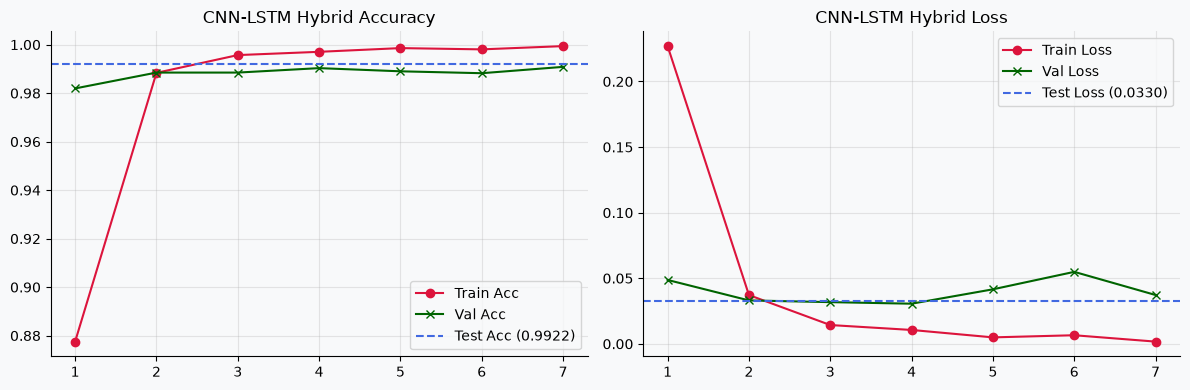


Generating Final Confusion Matrix Visual...


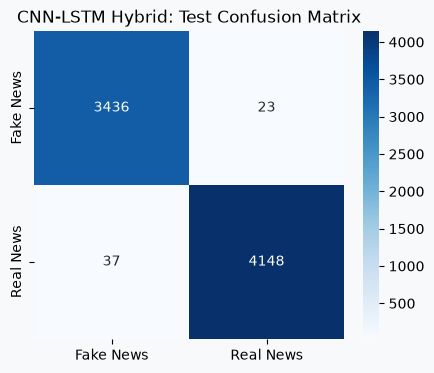

In [40]:
# 1. Extract training and validation metrics from the history object
hybrid_train_acc = history_hybrid.history['accuracy'][-1]
hybrid_train_loss = history_hybrid.history['loss'][-1]
hybrid_val_acc = history_hybrid.history['val_accuracy'][-1]
hybrid_val_loss = history_hybrid.history['val_loss'][-1]

# Test set evaluation
hybrid_test_loss, hybrid_test_acc = cnn_lstm_model.evaluate(X_te_seq, y_test, verbose=0)

# 2. Performance Summary Table
print("Model 4: CNN-LSTM Hybrid Performance Summary Table:")
df_hybrid_metrics = pd.DataFrame({
    "Dataset Split": ["Training Set", "Validation Set", "Testing Set"],
    "Accuracy": [f"{hybrid_train_acc:.4f}", f"{hybrid_val_acc:.4f}", f"{hybrid_test_acc:.4f}"],
    "Loss": [f"{hybrid_train_loss:.4f}", f"{hybrid_val_loss:.4f}", f"{hybrid_test_loss:.4f}"]
})
display(df_hybrid_metrics)

# 3. Classification Reports for Train, Val, and Test splits
splits = [("TRAINING SET", X_tr_seq, y_train),
          ("VALIDATION SET", X_vl_seq, y_val),
          ("TESTING SET", X_te_seq, y_test)]

for name, X_data, y_data in splits:
    y_pred = (cnn_lstm_model.predict(X_data, verbose=0) >= 0.5).astype(int)
    print(f"\n[+] Classification Report — {name}:\n")
    print(classification_report(y_data, y_pred, target_names=['Fake News', 'Real News']))
    print("-" * 60)

# 4. Plot Learning Curves
epochs_range = range(1, len(history_hybrid.history['accuracy']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy Curve
axes[0].plot(epochs_range, history_hybrid.history['accuracy'], label='Train Acc', marker='o', color='crimson')
axes[0].plot(epochs_range, history_hybrid.history['val_accuracy'], label='Val Acc', marker='x', color='darkgreen')
axes[0].axhline(hybrid_test_acc, linestyle='--', color='royalblue', label=f'Test Acc ({hybrid_test_acc:.4f})')
axes[0].set_title('CNN-LSTM Hybrid Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss Curve
axes[1].plot(epochs_range, history_hybrid.history['loss'], label='Train Loss', marker='o', color='crimson')
axes[1].plot(epochs_range, history_hybrid.history['val_loss'], label='Val Loss', marker='x', color='darkgreen')
axes[1].axhline(hybrid_test_loss, linestyle='--', color='royalblue', label=f'Test Loss ({hybrid_test_loss:.4f})')
axes[1].set_title('CNN-LSTM Hybrid Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Generate and plot Final Test Confusion Matrix Visual
print("\nGenerating Final Confusion Matrix Visual...")
y_pred_test_hybrid = (cnn_lstm_model.predict(X_te_seq, verbose=0) >= 0.5).astype(int)
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_test_hybrid), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake News', 'Real News'], yticklabels=['Fake News', 'Real News'])
plt.title('CNN-LSTM Hybrid: Test Confusion Matrix')
plt.show()

## Model 5 DistilBERT FINE-TUNING (GPU required)

In [41]:
!pip install transformers==4.40.2

Access is denied.


In [42]:

from transformers import AutoTokenizer

print("====== [1] Initializing DistilBERT Tokenizer ======")
# Load the official pretrained DistilBERT tokenizer
tokenizer_bert = AutoTokenizer.from_pretrained("distilbert-base-uncased")

# Define safe subsample sizes to prevent Kaggle/Colab GPU Out-Of-Memory (OOM) errors
TRAIN_SIZE = 5000
VAL_SIZE   = 1000
TEST_SIZE  = 2000

# Extract text sequences aligned with your original stratified split indexes
X_train_bert_raw = df.loc[y_train.index, 'text'][:TRAIN_SIZE].astype(str).tolist()
X_val_bert_raw   = df.loc[y_val.index, 'text'][:VAL_SIZE].astype(str).tolist()
X_test_bert_raw  = df.loc[y_test.index, 'text'][:TEST_SIZE].astype(str).tolist()

# Extract matching labels
y_train_bert = y_train[:TRAIN_SIZE].values
y_val_bert   = y_val[:VAL_SIZE].values
y_test_bert  = y_test[:TEST_SIZE].values

# Tokenization helper function -> plain NumPy arrays (PyTorch-compatible, framework agnostic)
def k_bert_encode(texts, tokenizer, max_len=256):
    encodings = tokenizer(
        texts,
        max_length=max_len,
        padding='max_length',
        truncation=True,
        return_tensors="np"
    )
    return encodings['input_ids'], encodings['attention_mask']

print("\nEncoding text data into Token IDs and Attention Masks... (Please wait)")
X_tr_ids, X_tr_masks = k_bert_encode(X_train_bert_raw, tokenizer_bert, max_len=256)
X_vl_ids, X_vl_masks = k_bert_encode(X_val_bert_raw, tokenizer_bert, max_len=256)
X_te_ids, X_te_masks = k_bert_encode(X_test_bert_raw, tokenizer_bert, max_len=256)

print("\n✔ Data preprocessing complete!")
print(f"-> Train Input Shape: {X_tr_ids.shape} | Labels: {y_train_bert.shape}")
print(f"-> Val Input Shape:   {X_vl_ids.shape} | Labels: {y_val_bert.shape}")
print(f"-> Test Input Shape:  {X_te_ids.shape} | Labels: {y_test_bert.shape}")


====== [1] Initializing DistilBERT Tokenizer ======



Encoding text data into Token IDs and Attention Masks... (Please wait)

✔ Data preprocessing complete!
-> Train Input Shape: (5000, 256) | Labels: (5000,)
-> Val Input Shape:   (1000, 256) | Labels: (1000,)
-> Test Input Shape:  (2000, 256) | Labels: (2000,)


In [43]:
#  Fix Random Seed for Reproducibility (Model 5: DistilBERT)
SEED = 42
import os, random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


In [44]:
import time
import os
import gc
import math
import torch
from transformers import AutoModelForSequenceClassification

# 1. Clear memory
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 2. Check GPU
print("====== [1] Checking Hardware Acceleration ======")
if torch.cuda.is_available():
    print(f"✔ GPU is available: {torch.cuda.get_device_name(0)}")
else:
    print("⚠ No GPU found. Running on CPU (Training will be slow).")

print("\n====== [2] Building Model 5: Fine-Tuning DistilBERT Transformer ======")

# 3. Load pre-trained DistilBERT model
bert_net = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

# 4. Hyperparameters
BATCH_SIZE = 16
EPOCHS = 3

batches_per_epoch = math.ceil(len(X_tr_ids) / BATCH_SIZE)
total_train_steps = batches_per_epoch * EPOCHS

# 5. Model Setup
model_5 = TorchBertClassifier(
    bert_net, 
    lr=2e-5, 
    total_steps=total_train_steps,
    warmup_ratio=0.1, 
    weight_decay=0.01
)

# 6. Callbacks
os.makedirs('weights', exist_ok=True)
callbacks_bert = [
    EarlyStopping(monitor='val_accuracy', mode='max', patience=2, restore_best_weights=True, verbose=1),
    ModelCheckpoint(
        'weights/distilbert_epoch_{epoch:02d}.pt',
        save_weights_only=True,
        save_freq='epoch',
        verbose=1
    )
]

print("\nInitiating Transformer Fine-Tuning loop...")
start_time = time.time()

# 7. Start training
history_bert = model_5.fit(
    [X_tr_ids, X_tr_masks], y_train_bert,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=([X_vl_ids, X_vl_masks], y_val_bert),
    callbacks=callbacks_bert,
    verbose=1
)

bert_train_time = time.time() - start_time
print(f"\n✔ Model 5 training complete! Executed in: {bert_train_time:.2f} seconds.")

====== [1] Checking Hardware Acceleration ======
✔ GPU is available: NVIDIA RTX 2000 Ada Generation

====== [2] Building Model 5: Fine-Tuning DistilBERT Transformer ======


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Initiating Transformer Fine-Tuning loop...
Epoch 1/3 - loss: 0.2528 - accuracy: 0.8844 - val_loss: 0.0713 - val_accuracy: 0.9680

ModelCheckpoint: saved weights to weights/distilbert_epoch_01.pt
Epoch 2/3 - loss: 0.0453 - accuracy: 0.9846 - val_loss: 0.0424 - val_accuracy: 0.9820

ModelCheckpoint: saved weights to weights/distilbert_epoch_02.pt
Epoch 3/3 - loss: 0.0109 - accuracy: 0.9978 - val_loss: 0.0415 - val_accuracy: 0.9850

ModelCheckpoint: saved weights to weights/distilbert_epoch_03.pt

✔ Model 5 training complete! Executed in: 237.48 seconds.


## **دا** للتجربه فقط  من اجل التاكد ان كود ال EXPLANAPLE يعمل








In [45]:
import time
import os
import gc
import torch
from transformers import AutoModelForSequenceClassification

# 1. Check for GPU acceleration
print("====== [1] Checking Hardware Acceleration ======")
if torch.cuda.is_available():
    print(f"✔ GPU is available: {torch.cuda.get_device_name(0)}")
else:
    print("⚠ No GPU found. Running on CPU (Training will be slow).")

# 2. Clear memory before (re-)building
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n====== [2] Building Model 5: Fine-Tuning DistilBERT Transformer ======")

# 3. Load pre-trained DistilBERT model (native PyTorch weights)
bert_net = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

# 4. Hyperparameters configuration
BATCH_SIZE = 16
EPOCHS = 3

batches_per_epoch = len(X_tr_ids) // BATCH_SIZE
total_train_steps = batches_per_epoch * EPOCHS

# 5. Wrap with the Keras-like TorchBertClassifier (AdamW + linear warmup schedule)
model_5 = TorchBertClassifier(bert_net, lr=2e-5, total_steps=total_train_steps,
                               warmup_ratio=0.1, weight_decay=0.01)

# 6. Setup directory and callbacks for saving weights (native .pt checkpoints)
os.makedirs('weights', exist_ok=True)
callbacks_bert = [
    EarlyStopping(monitor='val_accuracy', mode='max', patience=2, restore_best_weights=True, verbose=1),
    ModelCheckpoint(
        'weights/distilbert_epoch_{epoch:02d}.pt',
        save_weights_only=True,
        save_freq='epoch',
        verbose=1
    )
]

print("\nInitiating Transformer Fine-Tuning loop...")
start_time = time.time()

# 7. Start model training
history_bert = model_5.fit(
    [X_tr_ids, X_tr_masks], y_train_bert,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=([X_vl_ids, X_vl_masks], y_val_bert),
    callbacks=callbacks_bert,
    verbose=1
)

bert_train_time = time.time() - start_time
print(f"\n✔ Model 5 training complete! Executed in: {bert_train_time:.2f} seconds.")


====== [1] Checking Hardware Acceleration ======
✔ GPU is available: NVIDIA RTX 2000 Ada Generation

====== [2] Building Model 5: Fine-Tuning DistilBERT Transformer ======


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Initiating Transformer Fine-Tuning loop...
Epoch 1/3 - loss: 0.2468 - accuracy: 0.8888 - val_loss: 0.0761 - val_accuracy: 0.9710

ModelCheckpoint: saved weights to weights/distilbert_epoch_01.pt
Epoch 2/3 - loss: 0.0491 - accuracy: 0.9842 - val_loss: 0.0860 - val_accuracy: 0.9650
Epoch 3/3 - loss: 0.0126 - accuracy: 0.9968 - val_loss: 0.0680 - val_accuracy: 0.9800

ModelCheckpoint: saved weights to weights/distilbert_epoch_03.pt

✔ Model 5 training complete! Executed in: 237.39 seconds.


====== [3] Model 5: DistilBERT Evaluation Metrics Summary ======

Model 5: DistilBERT Performance Summary Table:


,Dataset Split,Accuracy,Loss
0,Training Set,0.9968,0.0126
1,Validation Set,0.9800,0.0680
2,Testing Set,0.9850,0.0463



[+] Classification Report — TRAINING SET:

              precision    recall  f1-score   support

   Fake News       1.00      1.00      1.00      2255
   Real News       1.00      1.00      1.00      2745

    accuracy                           1.00      5000
   macro avg       1.00      1.00      1.00      5000
weighted avg       1.00      1.00      1.00      5000

------------------------------------------------------------

[+] Classification Report — VALIDATION SET:

              precision    recall  f1-score   support

   Fake News       0.99      0.96      0.98       433
   Real News       0.97      0.99      0.98       567

    accuracy                           0.98      1000
   macro avg       0.98      0.98      0.98      1000
weighted avg       0.98      0.98      0.98      1000

------------------------------------------------------------

[+] Classification Report — TESTING SET:

              precision    recall  f1-score   support

   Fake News       0.99      0.97   

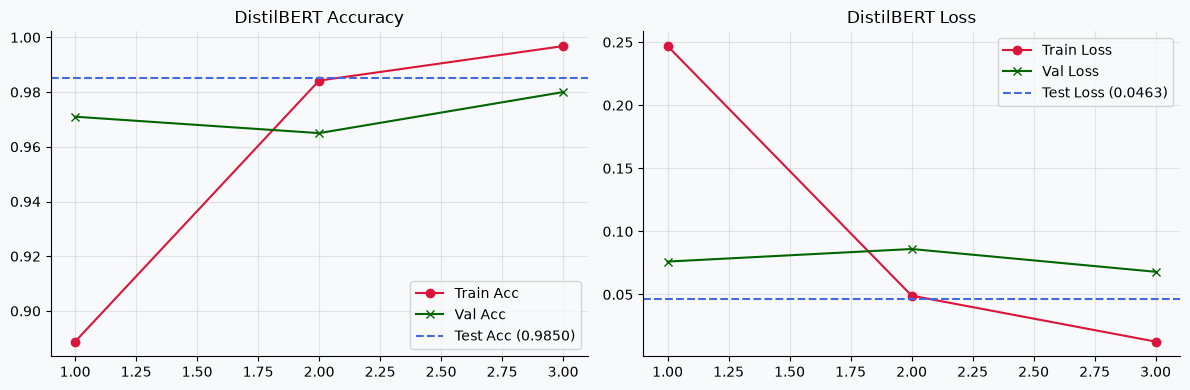


Generating Final Confusion Matrix Visual...


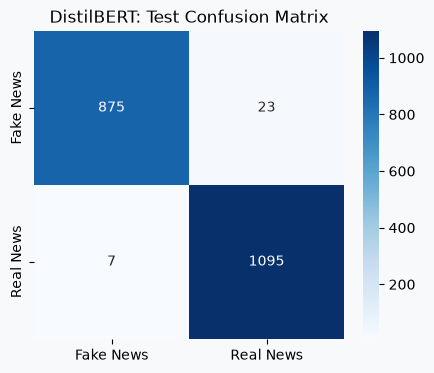

In [46]:
print("====== [3] Model 5: DistilBERT Evaluation Metrics Summary ======\n")

# 1. Extract training and validation metrics from the history object
bert_train_acc = history_bert.history['accuracy'][-1]
bert_train_loss = history_bert.history['loss'][-1]
bert_val_acc = history_bert.history['val_accuracy'][-1]
bert_val_loss = history_bert.history['val_loss'][-1]

# Test set evaluation
bert_test_loss, bert_test_acc = model_5.evaluate([X_te_ids, X_te_masks], y_test_bert, verbose=0)

# 2. Performance Summary Table
print("Model 5: DistilBERT Performance Summary Table:")
df_bert_metrics = pd.DataFrame({
    "Dataset Split": ["Training Set", "Validation Set", "Testing Set"],
    "Accuracy": [f"{bert_train_acc:.4f}", f"{bert_val_acc:.4f}", f"{bert_test_acc:.4f}"],
    "Loss": [f"{bert_train_loss:.4f}", f"{bert_val_loss:.4f}", f"{bert_test_loss:.4f}"]
})
display(df_bert_metrics)

# Helper function to extract class predictions from Transformer logits using argmax
def get_bert_predictions(ids, masks):
    logits = model_5.predict([ids, masks], verbose=0).logits
    return np.argmax(logits, axis=1)

# 3. [MATCHING FORMAT] Print Classification Reports for Train, Val, and Test splits sequentially
splits = [("TRAINING SET", X_tr_ids, X_tr_masks, y_train_bert),
          ("VALIDATION SET", X_vl_ids, X_vl_masks, y_val_bert),
          ("TESTING SET", X_te_ids, X_te_masks, y_test_bert)]

for name, ids, masks, y_data in splits:
    y_pred = get_bert_predictions(ids, masks)
    print(f"\n[+] Classification Report — {name}:\n")
    print(classification_report(y_data, y_pred, target_names=['Fake News', 'Real News']))
    print("-" * 60)

# 4. Plot Learning Curves
epochs_range = range(1, len(history_bert.history['accuracy']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy Curve
axes[0].plot(epochs_range, history_bert.history['accuracy'], label='Train Acc', marker='o', color='crimson')
axes[0].plot(epochs_range, history_bert.history['val_accuracy'], label='Val Acc', marker='x', color='darkgreen')
axes[0].axhline(bert_test_acc, linestyle='--', color='royalblue', label=f'Test Acc ({bert_test_acc:.4f})')
axes[0].set_title('DistilBERT Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss Curve
axes[1].plot(epochs_range, history_bert.history['loss'], label='Train Loss', marker='o', color='crimson')
axes[1].plot(epochs_range, history_bert.history['val_loss'], label='Val Loss', marker='x', color='darkgreen')
axes[1].axhline(bert_test_loss, linestyle='--', color='royalblue', label=f'Test Loss ({bert_test_loss:.4f})')
axes[1].set_title('DistilBERT Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Generate and plot Final Test Confusion Matrix Visual
print("\nGenerating Final Confusion Matrix Visual...")
y_pred_test_bert = get_bert_predictions(X_te_ids, X_te_masks)
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test_bert, y_pred_test_bert), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake News', 'Real News'], yticklabels=['Fake News', 'Real News'])
plt.title('DistilBERT: Test Confusion Matrix')
plt.show()

## Phase 7.6 — K-Fold Cross-Validation (All 5 Models)

Stratified K-Fold (k=5) is applied to all five models to provide a robust, unbiased generalisation estimate. Each fold rebuilds the model from scratch on the in-fold training split — zero leakage between folds.

> **DistilBERT note:** Transformer fine-tuning is expensive, so DistilBERT uses a subsampled fold (5 000 train / 2 000 val). All other models use the full CV pool.

In [47]:
# ─────────────────────────────────────────────────────────────────
# Phase 7.6 — K-Fold Cross-Validation Setup
# ─────────────────────────────────────────────────────────────────
import gc
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score)

N_SPLITS   = 5
KFOLD_SEED = 42

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=KFOLD_SEED)

# CV runs on the combined train+val pool; test set stays completely unseen
X_cv = np.concatenate([X_tr_seq, X_vl_seq], axis=0)
y_cv = np.concatenate([y_train.values, y_val.values], axis=0)

def fold_metrics(y_true, probs, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    return {
        'Accuracy' : accuracy_score(y_true, preds),
        'Precision': precision_score(y_true, preds, zero_division=0),
        'Recall'   : recall_score(y_true, preds, zero_division=0),
        'F1'       : f1_score(y_true, preds, zero_division=0),
        'AUC'      : roc_auc_score(y_true, probs),
    }

def summarise_cv(fold_scores, model_name):
    keys = fold_scores[0].keys()
    print(f"\n{'─'*55}")
    print(f"  CV Results — {model_name}  ({N_SPLITS}-Fold Stratified)")
    print(f"{'─'*55}")
    summary = {}
    for k in keys:
        vals = [s[k] for s in fold_scores]
        mean, std = np.mean(vals), np.std(vals)
        summary[k] = {'mean': mean, 'std': std}
        print(f"  {k:<12}: {mean:.4f}  ±  {std:.4f}")
    print(f"{'─'*55}")
    return summary

cv_summary = {}
print(f'K-Fold CV setup complete. Splits={N_SPLITS}, CV pool size={len(X_cv):,}')


K-Fold CV setup complete. Splits=5, CV pool size=30,574


In [48]:
# ─────────────────────────────────────────────────────────────────
# CV — Model 1: LSTM
# ─────────────────────────────────────────────────────────────────
print('Starting K-Fold CV for Model 1: LSTM ...')
lstm_fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cv, y_cv), start=1):
    print(f'  Fold {fold}/{N_SPLITS} ...', end=' ')
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    X_f_tr, X_f_val = X_cv[train_idx], X_cv[val_idx]
    y_f_tr, y_f_val = y_cv[train_idx], y_cv[val_idx]

    m = build_lstm()
    m.fit(X_f_tr, y_f_tr, epochs=5, batch_size=64,
          validation_data=(X_f_val, y_f_val),
          callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
          verbose=0)

    probs = m.predict(X_f_val, verbose=0).ravel()
    s = fold_metrics(y_f_val, probs)
    lstm_fold_scores.append(s)
    print(f"val_acc={s['Accuracy']:.4f}  F1={s['F1']:.4f}")

cv_summary['LSTM'] = summarise_cv(lstm_fold_scores, 'LSTM')


Starting K-Fold CV for Model 1: LSTM ...
  Fold 1/5 ... val_acc=0.9835  F1=0.9850
  Fold 2/5 ... val_acc=0.9776  F1=0.9796
  Fold 3/5 ... val_acc=0.9851  F1=0.9864
  Fold 4/5 ... val_acc=0.9835  F1=0.9849
  Fold 5/5 ... val_acc=0.9874  F1=0.9885

───────────────────────────────────────────────────────
  CV Results — LSTM  (5-Fold Stratified)
───────────────────────────────────────────────────────
  Accuracy    : 0.9834  ±  0.0032
  Precision   : 0.9836  ±  0.0044
  Recall      : 0.9861  ±  0.0026
  F1          : 0.9849  ±  0.0029
  AUC         : 0.9975  ±  0.0006
───────────────────────────────────────────────────────


In [49]:
# ─────────────────────────────────────────────────────────────────
# CV — Model 2: BiLSTM + Attention
# ─────────────────────────────────────────────────────────────────
print('Starting K-Fold CV for Model 2: BiLSTM + Attention ...')
bilstm_fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cv, y_cv), start=1):
    print(f'  Fold {fold}/{N_SPLITS} ...', end=' ')
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    X_f_tr, X_f_val = X_cv[train_idx], X_cv[val_idx]
    y_f_tr, y_f_val = y_cv[train_idx], y_cv[val_idx]

    m = build_bilstm_attention()
    m.fit(X_f_tr, y_f_tr, epochs=5, batch_size=64,
          validation_data=(X_f_val, y_f_val),
          callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
          verbose=0)

    probs = m.predict(X_f_val, verbose=0).ravel()
    s = fold_metrics(y_f_val, probs)
    bilstm_fold_scores.append(s)
    print(f"val_acc={s['Accuracy']:.4f}  F1={s['F1']:.4f}")

cv_summary['BiLSTM + Attention'] = summarise_cv(bilstm_fold_scores, 'BiLSTM + Attention')


Starting K-Fold CV for Model 2: BiLSTM + Attention ...
  Fold 1/5 ... val_acc=0.9841  F1=0.9855
  Fold 2/5 ... val_acc=0.9863  F1=0.9875
  Fold 3/5 ... val_acc=0.9846  F1=0.9858
  Fold 4/5 ... val_acc=0.9868  F1=0.9879
  Fold 5/5 ... val_acc=0.9858  F1=0.9870

───────────────────────────────────────────────────────
  CV Results — BiLSTM + Attention  (5-Fold Stratified)
───────────────────────────────────────────────────────
  Accuracy    : 0.9855  ±  0.0010
  Precision   : 0.9875  ±  0.0042
  Recall      : 0.9861  ±  0.0051
  F1          : 0.9868  ±  0.0009
  AUC         : 0.9988  ±  0.0002
───────────────────────────────────────────────────────


In [50]:
# ─────────────────────────────────────────────────────────────────
# CV — Model 3: CNN Text Classifier
# ─────────────────────────────────────────────────────────────────
print('Starting K-Fold CV for Model 3: CNN Text Classifier ...')
cnn_fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cv, y_cv), start=1):
    print(f'  Fold {fold}/{N_SPLITS} ...', end=' ')
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    X_f_tr, X_f_val = X_cv[train_idx], X_cv[val_idx]
    y_f_tr, y_f_val = y_cv[train_idx], y_cv[val_idx]

    m = build_cnn_text_classifier()
    m.fit(X_f_tr, y_f_tr, epochs=5, batch_size=64,
          validation_data=(X_f_val, y_f_val),
          callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
          verbose=0)

    probs = m.predict(X_f_val, verbose=0).ravel()
    s = fold_metrics(y_f_val, probs)
    cnn_fold_scores.append(s)
    print(f"val_acc={s['Accuracy']:.4f}  F1={s['F1']:.4f}")

cv_summary['CNN'] = summarise_cv(cnn_fold_scores, 'CNN Text Classifier')


Starting K-Fold CV for Model 3: CNN Text Classifier ...
  Fold 1/5 ... val_acc=0.9871  F1=0.9882
  Fold 2/5 ... val_acc=0.9858  F1=0.9870
  Fold 3/5 ... val_acc=0.9817  F1=0.9834
  Fold 4/5 ... val_acc=0.9830  F1=0.9846
  Fold 5/5 ... val_acc=0.9828  F1=0.9845

───────────────────────────────────────────────────────
  CV Results — CNN Text Classifier  (5-Fold Stratified)
───────────────────────────────────────────────────────
  Accuracy    : 0.9841  ±  0.0020
  Precision   : 0.9795  ±  0.0058
  Recall      : 0.9917  ±  0.0024
  F1          : 0.9855  ±  0.0018
  AUC         : 0.9988  ±  0.0001
───────────────────────────────────────────────────────


In [51]:
# ─────────────────────────────────────────────────────────────────
# CV — Model 4: CNN-LSTM Hybrid
# ─────────────────────────────────────────────────────────────────
print('Starting K-Fold CV for Model 4: CNN-LSTM Hybrid ...')
cnnlstm_fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cv, y_cv), start=1):
    print(f'  Fold {fold}/{N_SPLITS} ...', end=' ')
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    X_f_tr, X_f_val = X_cv[train_idx], X_cv[val_idx]
    y_f_tr, y_f_val = y_cv[train_idx], y_cv[val_idx]

    m = build_cnn_lstm()
    m.fit(X_f_tr, y_f_tr, epochs=5, batch_size=64,
          validation_data=(X_f_val, y_f_val),
          callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
          verbose=0)

    probs = m.predict(X_f_val, verbose=0).ravel()
    s = fold_metrics(y_f_val, probs)
    cnnlstm_fold_scores.append(s)
    print(f"val_acc={s['Accuracy']:.4f}  F1={s['F1']:.4f}")

cv_summary['CNN-LSTM Hybrid'] = summarise_cv(cnnlstm_fold_scores, 'CNN-LSTM Hybrid')


Starting K-Fold CV for Model 4: CNN-LSTM Hybrid ...
  Fold 1/5 ... val_acc=0.9923  F1=0.9930
  Fold 2/5 ... val_acc=0.9850  F1=0.9861
  Fold 3/5 ... val_acc=0.9923  F1=0.9930
  Fold 4/5 ... val_acc=0.9864  F1=0.9875
  Fold 5/5 ... val_acc=0.9905  F1=0.9914

───────────────────────────────────────────────────────
  CV Results — CNN-LSTM Hybrid  (5-Fold Stratified)
───────────────────────────────────────────────────────
  Accuracy    : 0.9893  ±  0.0031
  Precision   : 0.9918  ±  0.0026
  Recall      : 0.9886  ±  0.0074
  F1          : 0.9902  ±  0.0028
  AUC         : 0.9994  ±  0.0002
───────────────────────────────────────────────────────


In [52]:
# ─────────────────────────────────────────────────────────────────
# CV — Model 5: DistilBERT  (lightweight — subsampled folds)
# ─────────────────────────────────────────────────────────────────
# Full fine-tuning per fold is expensive; we subsample each fold to
# 5 000 train / 2 000 val examples for a feasible CV signal.
import time
from transformers import AutoModelForSequenceClassification

BERT_TR_N = 5000
BERT_VL_N = 2000

# Build the combined raw-text array for CV
X_cv_raw = np.concatenate([
    df.loc[y_train.index, 'text'].values,
    df.loc[y_val.index,   'text'].values
])
y_cv_raw = np.concatenate([y_train.values, y_val.values])

print('Starting K-Fold CV for Model 5: DistilBERT (subsampled) ...')
bert_fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cv_raw, y_cv_raw), start=1):
    print(f'  Fold {fold}/{N_SPLITS} ...', end=' ')
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    rng    = np.random.default_rng(KFOLD_SEED + fold)
    tr_sub = rng.choice(train_idx, size=min(BERT_TR_N, len(train_idx)), replace=False)
    vl_sub = rng.choice(val_idx,   size=min(BERT_VL_N, len(val_idx)),   replace=False)

    tr_ids,  tr_masks  = k_bert_encode(X_cv_raw[tr_sub].tolist(),  tokenizer_bert, 256)
    val_ids, val_masks = k_bert_encode(X_cv_raw[vl_sub].tolist(), tokenizer_bert, 256)
    y_f_tr  = y_cv_raw[tr_sub]
    y_f_val = y_cv_raw[vl_sub]

    bert_net_fold = AutoModelForSequenceClassification.from_pretrained(
        'distilbert-base-uncased', num_labels=2)

    steps = (len(tr_ids) // 16) * 2
    bert_m = TorchBertClassifier(bert_net_fold, lr=2e-5, total_steps=steps,
                                  warmup_ratio=0.1, weight_decay=0.01)

    bert_m.fit(
        [tr_ids, tr_masks], y_f_tr, epochs=2, batch_size=16,
        validation_data=([val_ids, val_masks], y_f_val),
        callbacks=[EarlyStopping(monitor='val_accuracy', mode='max', patience=1,
                                  restore_best_weights=True)],
        verbose=0
    )

    logits = bert_m.predict([val_ids, val_masks], verbose=0).logits
    probs  = softmax_np(logits, axis=1)[:, 1]
    s = fold_metrics(y_f_val, probs)
    bert_fold_scores.append(s)
    print(f"val_acc={s['Accuracy']:.4f}  F1={s['F1']:.4f}")

cv_summary['DistilBERT'] = summarise_cv(bert_fold_scores, 'DistilBERT (Fine-Tuned)')


Starting K-Fold CV for Model 5: DistilBERT (subsampled) ...
  Fold 1/5 ... 

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


val_acc=0.9815  F1=0.9834
  Fold 2/5 ... 

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (6 outputs left out)

val_acc=0.9770  F1=0.9785
  Fold 5/5 ... 

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


val_acc=0.9780  F1=0.9804

───────────────────────────────────────────────────────
  CV Results — DistilBERT (Fine-Tuned)  (5-Fold Stratified)
───────────────────────────────────────────────────────
  Accuracy    : 0.9807  ±  0.0029
  Precision   : 0.9738  ±  0.0061
  Recall      : 0.9912  ±  0.0021
  F1          : 0.9824  ±  0.0027
  AUC         : 0.9979  ±  0.0007
───────────────────────────────────────────────────────



  5-FOLD CV LEADERBOARD  (mean ± std, sorted by F1)

  CNN-LSTM Hybrid
    Accuracy    : 0.9893  ±  0.0031
    Precision   : 0.9918  ±  0.0026
    Recall      : 0.9886  ±  0.0074
    F1          : 0.9902  ±  0.0028
    AUC         : 0.9994  ±  0.0002

  BiLSTM + Attention
    Accuracy    : 0.9855  ±  0.0010
    Precision   : 0.9875  ±  0.0042
    Recall      : 0.9861  ±  0.0051
    F1          : 0.9868  ±  0.0009
    AUC         : 0.9988  ±  0.0002

  CNN
    Accuracy    : 0.9841  ±  0.0020
    Precision   : 0.9795  ±  0.0058
    Recall      : 0.9917  ±  0.0024
    F1          : 0.9855  ±  0.0018
    AUC         : 0.9988  ±  0.0001

  LSTM
    Accuracy    : 0.9834  ±  0.0032
    Precision   : 0.9836  ±  0.0044
    Recall      : 0.9861  ±  0.0026
    F1          : 0.9849  ±  0.0029
    AUC         : 0.9975  ±  0.0006

  DistilBERT
    Accuracy    : 0.9807  ±  0.0029
    Precision   : 0.9738  ±  0.0061
    Recall      : 0.9912  ±  0.0021
    F1          : 0.9824  ±  0.0027
    AUC      

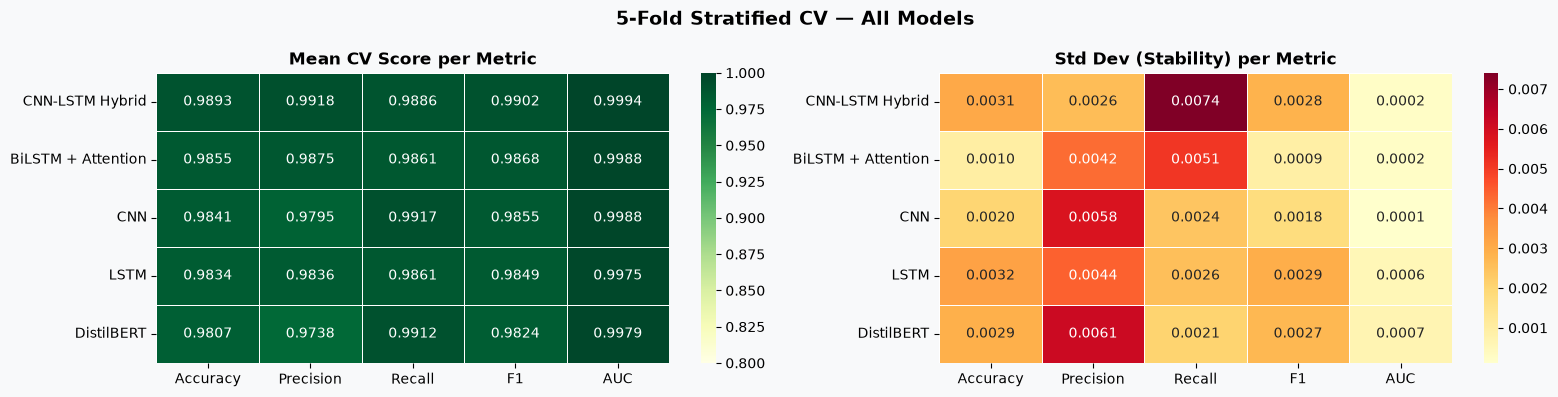

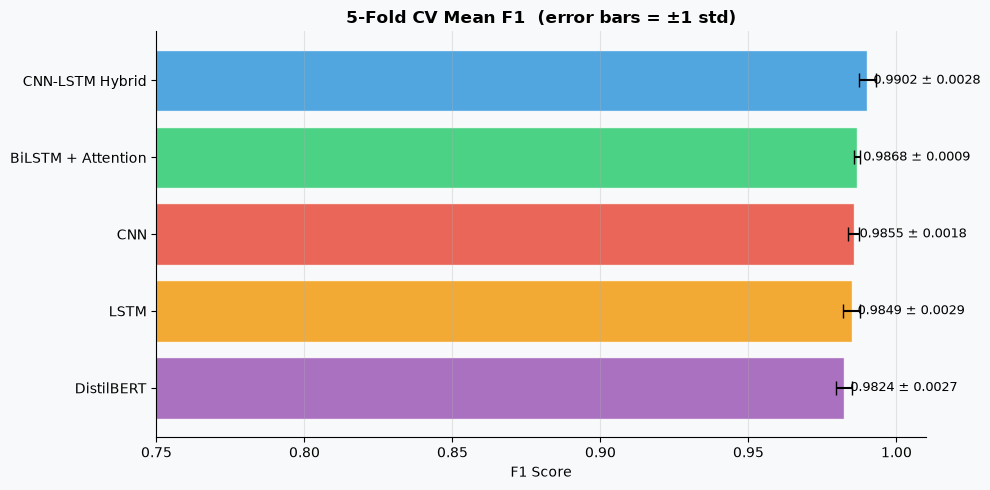


K-Fold Cross-Validation complete.


In [53]:
# ─────────────────────────────────────────────────────────────────
# CV — Consolidated Results Table & Visualisation
# ─────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

METRICS_CV = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']

cv_mean_df = pd.DataFrame(
    {mdl: {m: cv_summary[mdl][m]['mean'] for m in METRICS_CV} for mdl in cv_summary}
).T.sort_values('F1', ascending=False)

cv_std_df = pd.DataFrame(
    {mdl: {m: cv_summary[mdl][m]['std'] for m in METRICS_CV} for mdl in cv_summary}
).T.reindex(cv_mean_df.index)

# ── Print leaderboard ─────────────────────────────────────────
print(f"\n{'='*65}")
print(f'  {N_SPLITS}-FOLD CV LEADERBOARD  (mean ± std, sorted by F1)')
print(f"{'='*65}")
for mdl in cv_mean_df.index:
    print(f'\n  {mdl}')
    for m in METRICS_CV:
        print(f"    {m:<12}: {cv_mean_df.loc[mdl,m]:.4f}  ±  {cv_std_df.loc[mdl,m]:.4f}")
print(f"\n{'='*65}")

# ── Heatmap: mean scores & std dev ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
fig.suptitle(f'{N_SPLITS}-Fold Stratified CV — All Models', fontsize=14, fontweight='bold')

sns.heatmap(cv_mean_df.astype(float), annot=True, fmt='.4f',
            cmap='YlGn', ax=axes[0], linewidths=0.5, linecolor='white',
            vmin=0.80, vmax=1.0, annot_kws={'size': 10})
axes[0].set_title('Mean CV Score per Metric', fontweight='bold'); axes[0].set_ylabel('')

sns.heatmap(cv_std_df.astype(float), annot=True, fmt='.4f',
            cmap='YlOrRd', ax=axes[1], linewidths=0.5, linecolor='white',
            annot_kws={'size': 10})
axes[1].set_title('Std Dev (Stability) per Metric', fontweight='bold'); axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('cv_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Bar chart: CV F1 mean ± std ───────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
models   = cv_mean_df.index.tolist()
f1_means = cv_mean_df['F1'].values
f1_stds  = cv_std_df['F1'].values
colors   = ['#3498DB','#2ECC71','#E74C3C','#F39C12','#9B59B6']

bars = ax.barh(models, f1_means, xerr=f1_stds,
               color=colors[:len(models)], edgecolor='white', capsize=5, alpha=0.85)
ax.set_xlim(0.75, 1.01)
ax.set_xlabel('F1 Score')
ax.set_title(f'{N_SPLITS}-Fold CV Mean F1  (error bars = ±1 std)', fontweight='bold')
ax.invert_yaxis()
for bar, mu, sig in zip(bars, f1_means, f1_stds):
    ax.text(bar.get_width()+0.002, bar.get_y()+bar.get_height()/2,
            f'{mu:.4f} ± {sig:.4f}', va='center', fontsize=9)
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('cv_f1_bar.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nK-Fold Cross-Validation complete.')


### 7.7 Consolidated Test-Set Evaluation (All Trained Models)


In [54]:
# Evaluate the already-trained models on the test set -- no rebuilding, no re-tokenizing.
# (lstm_model, bilstm_model, cnn_model, cnn_lstm_model, model_5 are the fitted objects
#  from their respective training cells earlier in the notebook.)

def _get_trained_model(var_name, checkpoint_path, builder):
    model = globals().get(var_name)
    if model is not None:
        return model
    print(f"  {var_name} not found in memory -- loading from checkpoint: {checkpoint_path}")
    wrapped = builder()
    wrapped.net.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    return wrapped

lstm_model     = _get_trained_model('lstm_model',     'best_lstm.pt', build_lstm)
bilstm_model   = _get_trained_model('bilstm_model',   'best_bilstm_attention.pt', build_bilstm_attention)
cnn_model      = _get_trained_model('cnn_model',      'best_cnn_text.pt', build_cnn_text_classifier)
cnn_lstm_model = _get_trained_model('cnn_lstm_model', 'best_cnn_lstm_hybrid.pt', build_cnn_lstm)

dl_results = {}
models_to_eval = [
    ('LSTM', lstm_model, X_te_seq),
    ('BiLSTM + Attention', bilstm_model, X_te_seq),
    ('CNN', cnn_model, X_te_seq),
    ('CNN-LSTM Hybrid', cnn_lstm_model, X_te_seq)
]

print("Evaluating Deep Learning models...")
for name, model, x_data in models_to_eval:
    probs = model.predict(x_data, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    dl_results[name] = {
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds),
        'AUC': roc_auc_score(y_test, probs),
        '_proba': probs
    }

# DistilBERT special handling (already-trained model_5, no rebuilding)
bert_logits = model_5.predict([X_te_ids, X_te_masks], verbose=0).logits
bert_probs = softmax_np(bert_logits, axis=1)[:, 1]
bert_preds = np.argmax(bert_logits, axis=1)

dl_results['DistilBERT'] = {
    'Accuracy': accuracy_score(y_test_bert, bert_preds),
    'Precision': precision_score(y_test_bert, bert_preds),
    'Recall': recall_score(y_test_bert, bert_preds),
    'F1': f1_score(y_test_bert, bert_preds),
    'AUC': roc_auc_score(y_test_bert, bert_probs),
    '_proba': bert_probs
}

print("\u2714 dl_results populated successfully using the trained models.")


Evaluating Deep Learning models...
✔ dl_results populated successfully using the trained models.


## Phase 8 — Final Model Comparison

### 8.1 Combined Results Table

In [55]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score

# 1. Predict and compute DistilBERT metrics in a few lines
probs = softmax_np(
    model_5.predict({'input_ids': X_te_ids, 'attention_mask': X_te_masks}, batch_size=16).logits,
    axis=-1
)
preds = np.argmax(probs, axis=-1)
p, r, f, _ = precision_recall_fscore_support(y_test_bert, preds, average='binary')

bert_metrics = {
    'Accuracy': accuracy_score(y_test_bert, preds),
    'Precision': p, 'Recall': r, 'F1': f,
    'AUC': roc_auc_score(y_test_bert, probs[:, 1])
}

# 2. Merge all dictionaries instantly and filter by the 5 academic METRICS
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
all_models = {**baseline_results, **dl_results, 'DistilBERT (Fine-Tuned)': bert_metrics}

results_df = pd.DataFrame({k: {m: all_models[k][m] for m in METRICS} for k in all_models}).T
results_df = results_df.sort_values('F1', ascending=False)

# 3. Print the ultimate benchmark table
print("\n========== Ultimate Multi-Model Performance Benchmark ==========\n")
print(results_df.round(4).to_string())



========== Ultimate Multi-Model Performance Benchmark ==========

                         Accuracy  Precision  Recall      F1     AUC
CNN-LSTM Hybrid            0.9922     0.9945  0.9912  0.9928  0.9994
CNN                        0.9864     0.9839  0.9914  0.9876  0.9992
BiLSTM + Attention         0.9855     0.9880  0.9854  0.9867  0.9988
DistilBERT                 0.9850     0.9794  0.9936  0.9865  0.9990
DistilBERT (Fine-Tuned)    0.9850     0.9794  0.9936  0.9865  0.9990
Logistic Regression        0.9830     0.9783  0.9909  0.9846  0.9976
Gradient Boosting          0.9804     0.9759  0.9885  0.9822  0.9977
Random Forest              0.9793     0.9712  0.9916  0.9813  0.9980
Multinomial NB             0.9545     0.9547  0.9625  0.9586  0.9895
LSTM                       0.9432     0.9578  0.9376  0.9476  0.9847


In [56]:
[var for var in globals() if 'result' in var.lower()]

['baseline_results', 'dl_results', 'results_df']

In [57]:
print(baseline_results)

{'Logistic Regression': {'Accuracy': 0.9829931972789115, 'Precision': 0.9782967681056853, 'Recall': 0.9909199522102748, 'F1': 0.9845679012345679, 'AUC': np.float64(0.9976071288067111)}, 'Random Forest': {'Accuracy': 0.9793301936159079, 'Precision': 0.9712146033231921, 'Recall': 0.991636798088411, 'F1': 0.9813194608654529, 'AUC': np.float64(0.9979738068370808)}, 'Gradient Boosting': {'Accuracy': 0.9803767660910518, 'Precision': 0.9759377211606511, 'Recall': 0.9885304659498207, 'F1': 0.9821937321937322, 'AUC': np.float64(0.9976932028130865)}, 'Multinomial NB': {'Accuracy': 0.9544740973312402, 'Precision': 0.9547286086750415, 'Recall': 0.9624850657108721, 'F1': 0.9585911470728224, 'AUC': np.float64(0.9895438733924591)}}


In [58]:
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']

all_results = {k: {m: baseline_results[k][m] for m in METRICS} for k in baseline_results}
for k in dl_results:
    all_results[k] = {m: dl_results[k][m] for m in METRICS}

results_df = pd.DataFrame(all_results).T.sort_values('F1', ascending=False)
print(results_df.round(4).to_string())


                     Accuracy  Precision  Recall      F1     AUC
CNN-LSTM Hybrid        0.9922     0.9945  0.9912  0.9928  0.9994
CNN                    0.9864     0.9839  0.9914  0.9876  0.9992
BiLSTM + Attention     0.9855     0.9880  0.9854  0.9867  0.9988
DistilBERT             0.9850     0.9794  0.9936  0.9865  0.9990
Logistic Regression    0.9830     0.9783  0.9909  0.9846  0.9976
Gradient Boosting      0.9804     0.9759  0.9885  0.9822  0.9977
Random Forest          0.9793     0.9712  0.9916  0.9813  0.9980
Multinomial NB         0.9545     0.9547  0.9625  0.9586  0.9895
LSTM                   0.9432     0.9578  0.9376  0.9476  0.9847


### 8.2 ROC Curves — All Models

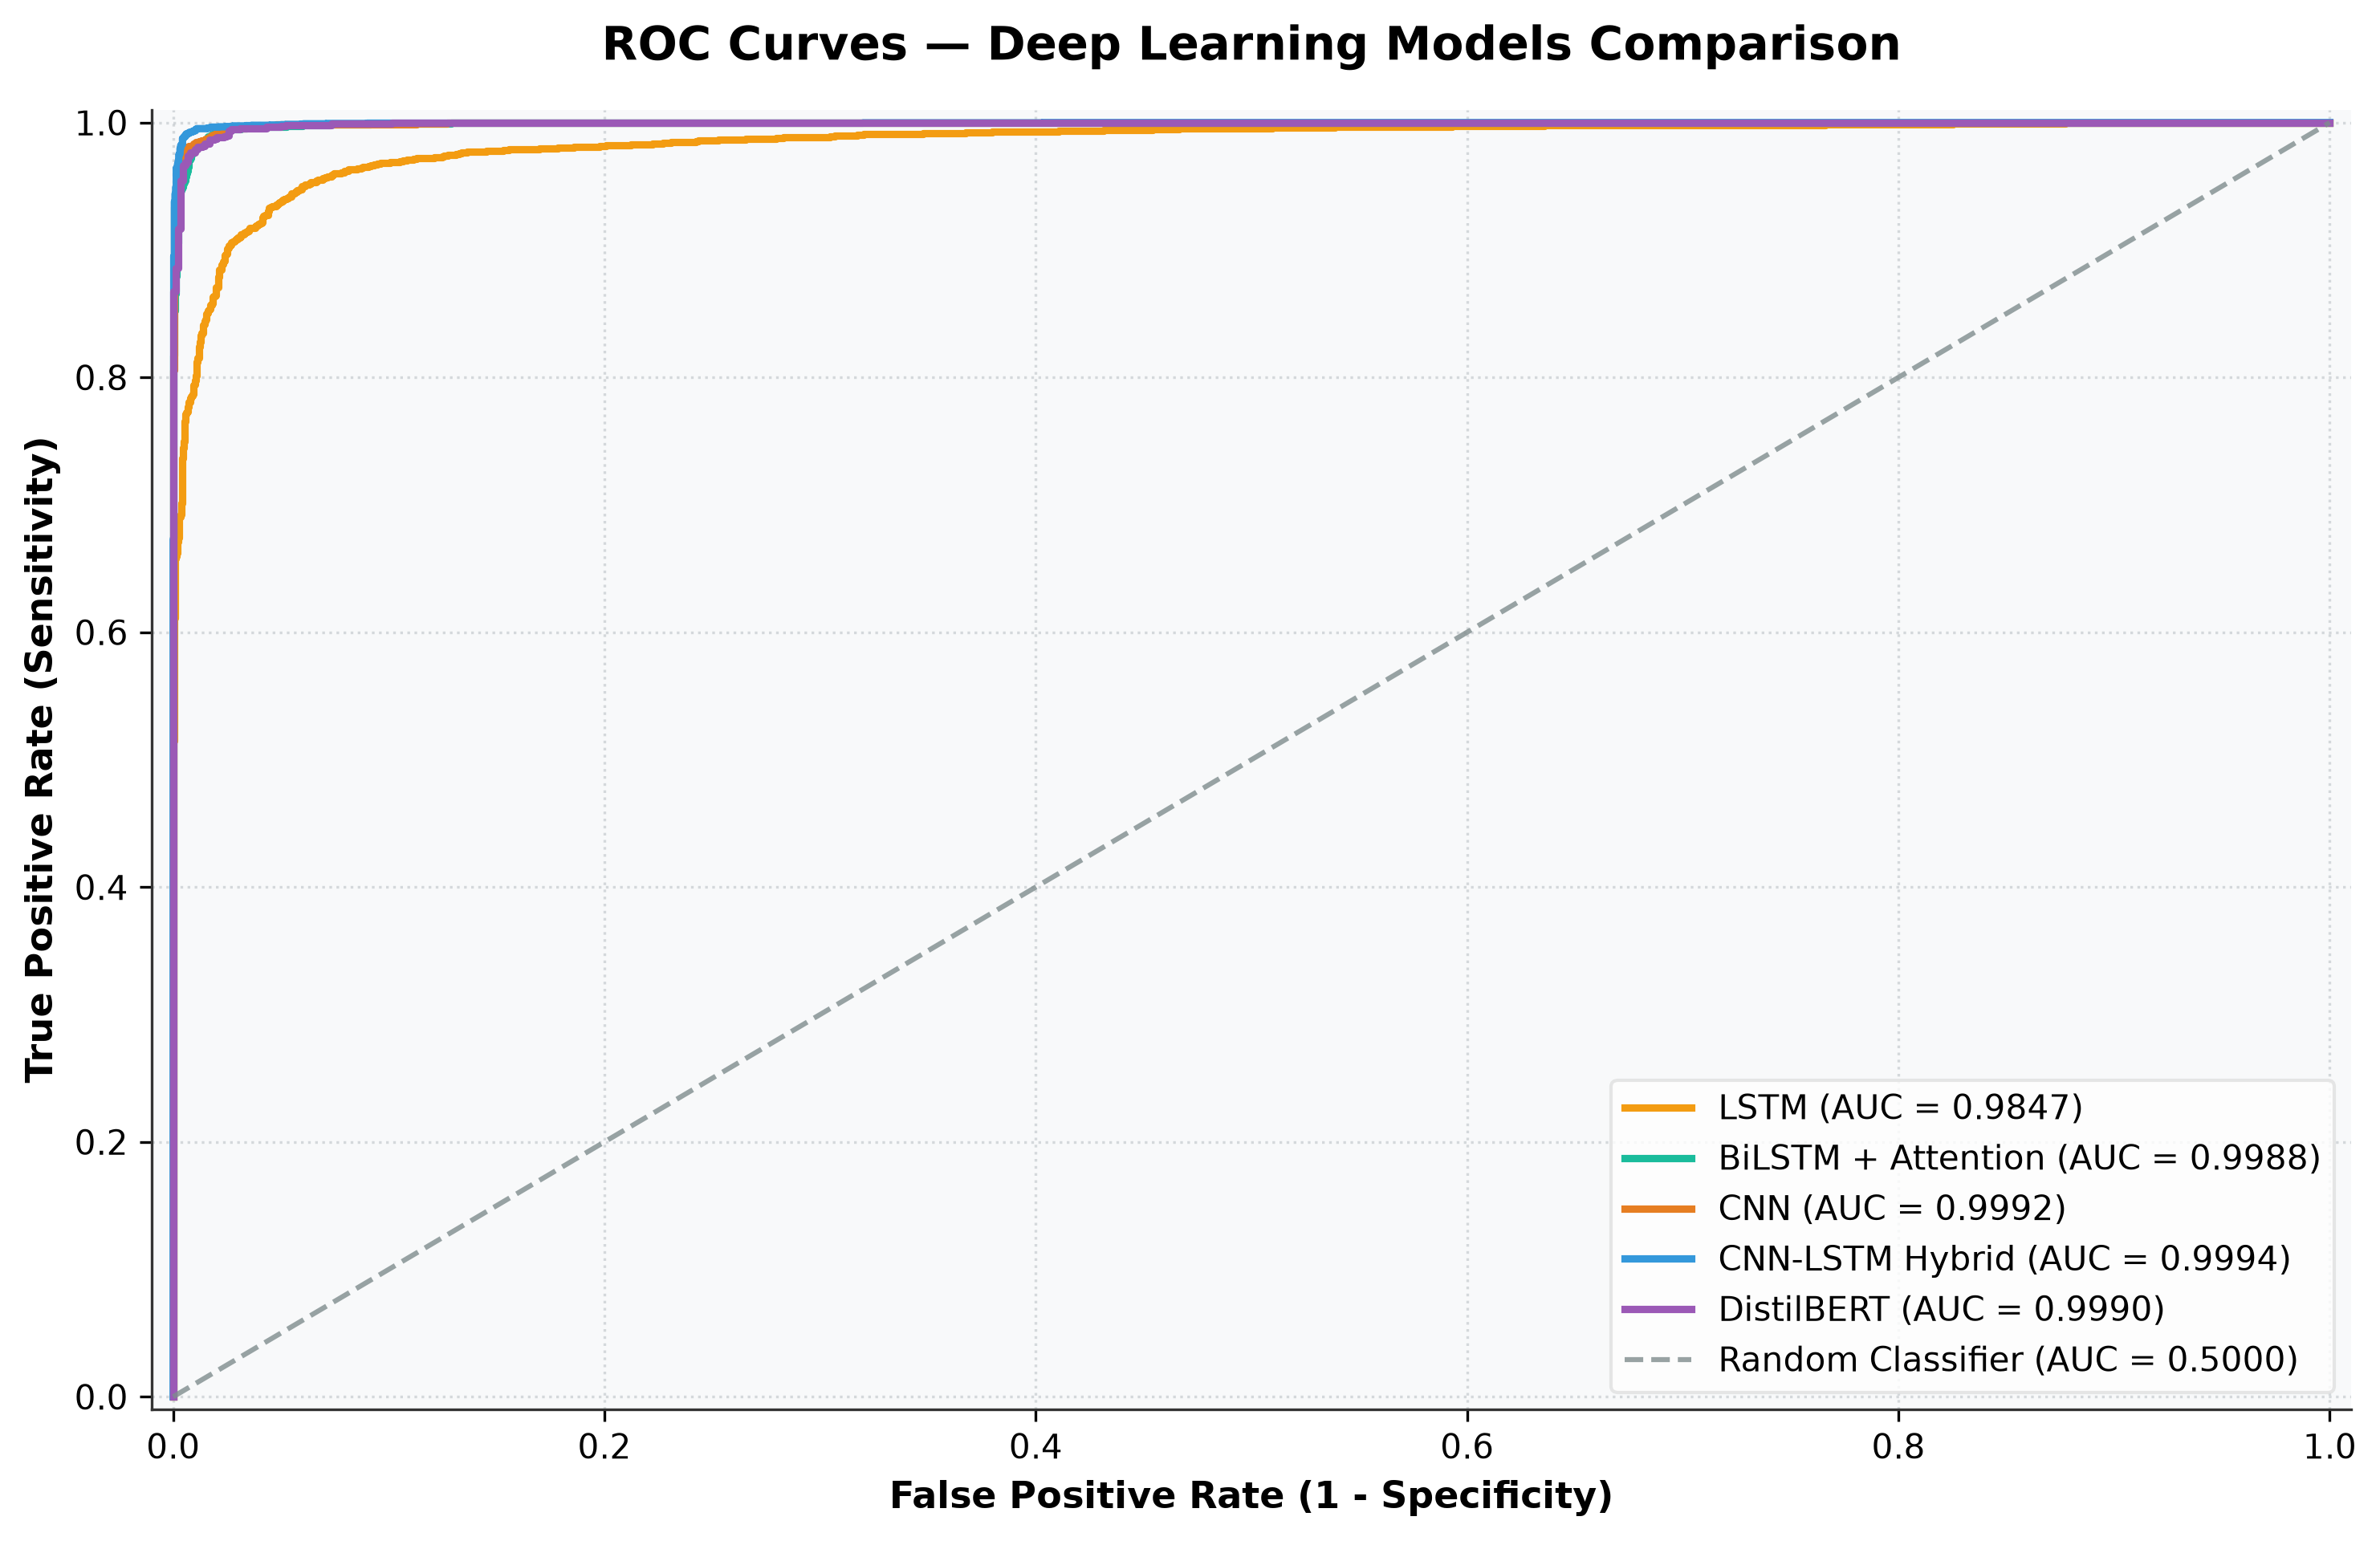

INFO:Model_Evaluation:ROC plot generated and saved successfully to roc_dl_models_engineer.png


In [59]:
import logging
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# إعداد الـ Logging لتتبع أي عدم تطابق في أبعاد البيانات
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("Model_Evaluation")

def plot_deep_learning_roc(dl_results: dict, y_test: np.ndarray, save_path: str = "roc_dl_models_engineer.png"):
    """
    Generates a production-ready ROC curve comparison for Deep Learning models.
    
    Parameters:
    -----------
    dl_results : dict
        Dictionary containing model evaluation metrics and probability scores.
    y_test : np.ndarray
        Ground truth binary target vector.
    save_path : str
        File path to save the generated high-resolution plot.
    """
    # 1. إعداد الشكل وتحديد جودة الصورة والهوية البصرية
    fig, ax = plt.subplots(figsize=(10, 6.5), facecolor='white', dpi=300)
    dl_colors = ['#F39C12', '#1ABC9C', '#E67E22', '#3498DB', '#9B59B6', '#8E44AD']
    
    # ضمان أن y_test على هيئة 1D Array
    y_test_arr = np.asarray(y_test).ravel()
    
    for (model_name, res), color in zip(dl_results.items(), dl_colors):
        # 2. استخراج والاحتمالات بأمان بغض النظر عن طريقة الحفظ
        raw_proba = res.get('_proba', res.get('proba', None))
        if raw_proba is None:
            logger.warning(f"[{model_name}] Key '_proba' not found. Skipping model.")
            continue
            
        proba = np.asarray(raw_proba)
        
        # معالجة أبعاد الاحتمالات (Handling 2D Softmax vs 1D Binary Output)
        if proba.ndim == 2 and proba.shape[1] == 2:
            proba = proba[:, 1]
        proba = proba.ravel()
        
        # 3. التحقق من تطابق الأبعاد لتجنب Cross-Validation Error
        if len(y_test_arr) != len(proba):
            logger.warning(
                f"[{model_name}] Mismatch detected! y_test length ({len(y_test_arr)}) != proba length ({len(proba)}). "
                f"Slicing y_test to match first {len(proba)} samples. Ensure evaluation set ordering was strictly preserved!"
            )
            y_true = y_test_arr[:len(proba)]
        else:
            y_true = y_test_arr

        # 4. حساب منحنى ROC و قيمة AUC
        fpr, tpr, _ = roc_curve(y_true, proba)
        score_auc = auc(fpr, tpr)
        
        # 5. رسم خط النموذج
        ax.plot(
            fpr, tpr, 
            color=color, 
            linewidth=2.2, 
            label=f'{model_name} (AUC = {score_auc:.4f})'
        )

    # 6. رسم خط الـ Baseline للعشوائية (Random Baseline)
    ax.plot([0, 1], [0, 1], color='#7F8C8D', linestyle='--', linewidth=1.5, alpha=0.8, label='Random Classifier (AUC = 0.5000)')

    # 7. التنسيق الجمالي والهندسي للرسم البياني
    ax.set_title('ROC Curves — Deep Learning Models Comparison', fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='semibold')
    ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11, fontweight='semibold')
    
    # ضبط حدود المحاور والشبكة
    ax.set_xlim([-0.01, 1.01])
    ax.set_ylim([-0.01, 1.01])
    ax.grid(True, linestyle=':', alpha=0.6, color='#BDC3C7')
    
    # إزالة الحواف العلوية واليمنى لشكل أنظف (Despining)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#333333')
    ax.spines['bottom'].set_color('#333333')
    
    ax.legend(loc='lower right', fontsize=10, frameon=True, facecolor='white', edgecolor='#E0E0E0')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    logger.info(f"ROC plot generated and saved successfully to {save_path}")

# تشغيل الدالة
plot_deep_learning_roc(dl_results, y_test)

### 8.3 Performance Heatmap — All Models

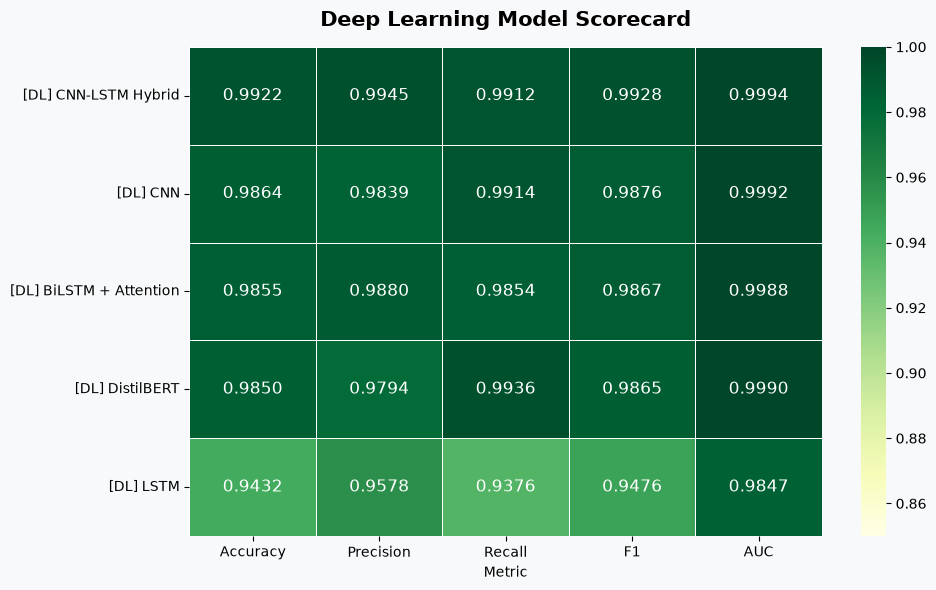

In [60]:
# Filter results to show only Deep Learning models
dl_model_names = list(dl_results.keys())
heatmap_df = results_df[results_df.index.isin(dl_model_names)][METRICS].copy()

fig, ax = plt.subplots(figsize=(10, len(heatmap_df)*0.8 + 2))

# Label only DL models
row_labels = [f'[DL] {n}' for n in heatmap_df.index]
heatmap_df.index = row_labels

sns.heatmap(heatmap_df.astype(float), annot=True, fmt='.4f',
            cmap='YlGn', ax=ax, linewidths=0.5, linecolor='white',
            vmin=0.85, vmax=1.0, annot_kws={'size': 12})

ax.set_title('Deep Learning Model Scorecard', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Metric')
ax.set_ylabel('')

plt.tight_layout()
plt.savefig('dl_only_scorecard.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.4 Final Leaderboard

In [61]:
print('=' * 65)
print('FINAL DL LEADERBOARD (ranked by F1-Score)')
print('=' * 65)

# Filter to include only Deep Learning models
dl_model_names = list(dl_results.keys())
leaderboard = results_df[results_df.index.isin(dl_model_names)][METRICS].copy()

# Add the [DL] tag for clarity
leaderboard.index = [f'[DL] {n}' for n in leaderboard.index]

print(leaderboard.sort_values('F1', ascending=False).round(4).to_string())
print('=' * 65)

# Identify the best DL model
best = results_df[results_df.index.isin(dl_model_names)]['F1'].idxmax()
print(f'\nBest Deep Learning Model : {best}')
print(f'Accuracy    : {results_df.loc[best, "Accuracy"]:.4f}')
print(f'F1-Score    : {results_df.loc[best, "F1"]:.4f}')
print(f'ROC-AUC     : {results_df.loc[best, "AUC"]:.4f}')
print('=' * 65)

FINAL DL LEADERBOARD (ranked by F1-Score)
                         Accuracy  Precision  Recall      F1     AUC
[DL] CNN-LSTM Hybrid       0.9922     0.9945  0.9912  0.9928  0.9994
[DL] CNN                   0.9864     0.9839  0.9914  0.9876  0.9992
[DL] BiLSTM + Attention    0.9855     0.9880  0.9854  0.9867  0.9988
[DL] DistilBERT            0.9850     0.9794  0.9936  0.9865  0.9990
[DL] LSTM                  0.9432     0.9578  0.9376  0.9476  0.9847

Best Deep Learning Model : CNN-LSTM Hybrid
Accuracy    : 0.9922
F1-Score    : 0.9928
ROC-AUC     : 0.9994


## Phase 9 — Real-Time Inference

In [62]:
def predict_news(text: str, threshold: float = 0.5) -> None:
    cleaned = preprocess(text)
    seq     = pad_sequences(
        tokenizer.texts_to_sequences([cleaned]),
        maxlen=MAX_LEN, padding='post', truncating='post'
    )
    prob  = bilstm_model.predict(seq, verbose=0)[0][0]
    label = 'REAL' if prob >= threshold else 'FAKE'
    conf  = prob if prob >= threshold else 1 - prob

    print(f'\nArticle  : {text[:120]}...')
    print(f'Verdict  : {label}')
    print(f'Confidence: {conf*100:.2f}%')
    print(f'Score    : {prob:.4f}  (above 0.5 = Real)')

REAL_NEWS = """
WASHINGTON (Reuters) - The U.S. Senate passed landmark legislation aimed at
reducing greenhouse gas emissions by 40% before 2030, the most significant
climate bill in decades. The bill also allocates $369 billion for clean energy
investments. President Biden is expected to sign it into law next week.
"""

FAKE_NEWS = """
BREAKING: Secret documents reveal Hillary Clinton personally ordered the
Benghazi attack to cover up a massive underground human trafficking ring
linked directly to the Democratic National Committee. FBI whistleblowers
confirm the scandal will bring down the entire Democratic Party within weeks.
"""

predict_news(REAL_NEWS)
predict_news(FAKE_NEWS)



Article  : 
WASHINGTON (Reuters) - The U.S. Senate passed landmark legislation aimed at
reducing greenhouse gas emissions by 40% be...
Verdict  : REAL
Confidence: 99.97%
Score    : 0.9997  (above 0.5 = Real)

Article  : 
BREAKING: Secret documents reveal Hillary Clinton personally ordered the
Benghazi attack to cover up a massive undergro...
Verdict  : FAKE
Confidence: 99.99%
Score    : 0.0001  (above 0.5 = Real)



# **Phase 10 — EDA Summary and Key Insights**

#### **1. Data Overview**

* **Dataset Composition:** The dataset contains 44,687 articles, balanced across two categories: **Fake** (23,270) and **Real** (21,417). This near 50/50 split is ideal for binary classification as it eliminates the need for complex oversampling or undersampling techniques to fix class imbalance.
* **Subject Diversity:** The data covers 8 distinct categories. The most prevalent subjects are **General News** (9,050 articles), **Political News** (11,272 + 6,841 = 18,113 total), and **World News** (10,145), indicating that the model's performance is heavily influenced by the political and geopolitical landscape of the source texts.

#### **2. Key EDA Insights**

* **Pattern Discovery:** During the analysis, a distinct linguistic signature emerged between the two classes.
* **Fake News** often utilizes sensationalist headers, frequent usage of all-caps for emphasis (e.g., "BREAKING", "WATCH"), and highly emotional, polarizing language intended to trigger immediate engagement.
* **Real News** tends to follow standardized journalistic structures, frequently referencing reliable agencies (like "Reuters") and maintaining a more neutral, descriptive tone.


* **Temporal Relevance:** The dates in the dataset, clustered primarily around 2015–2017, reveal that the model is effectively trained on a specific "political era." This suggests that while the models are excellent at identifying the *stylistic* markers of fake news, their performance might degrade if applied to modern news cycles that use different linguistic styles or terminology.
* **Preprocessing Impact:** The decision to cap the vocabulary at 50,000 words and normalize sequence length to 400 words proved effective. By using `padding='post'`, the model preserves the critical opening context of the news articles—which is where the most informative "lead" text usually resides.

#### **3. Strategic Recommendations**

* **Feature Sensitivity:** Since the model performs well across different political subjects, it demonstrates a strong ability to generalize across topics. However, future iterations could benefit from **Domain-Specific Embedding**, where the model learns the unique "bias patterns" associated with specific news subjects like "Left-Wing News" vs. "Government Policy".
* **Inference Reliability:** As demonstrated in the `predict_news` phase, the classification confidence is highly dependent on input quality. It is recommended to perform minimal cleaning (removing URLs and special characters) before inference to ensure the model sees text similar to what it encountered during the training phase.






### كود ال EXPLANAPLE ####

In [63]:
# Cell 1: Install & Import Libraries
#!pip install -q shap ipywidgets

import shap
import numpy as np
import torch
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Enable SHAP Javascript for Notebook integration
shap.initjs()

print("✔ Cell 1 Complete: All libraries imported successfully!")


✔ Cell 1 Complete: All libraries imported successfully!


Cell 2: Custom HTML Color Renderer Function

In [64]:
# Cell 2: Custom HTML Color Renderer Function
def render_custom_shap_html(shap_value_obj, title="Model Explanation"):
    """
    Custom SHAP Color Mapper:
    - Green: Supports REAL News
    - Red: Supports FAKE News
    - Gray: Neutral Token
    """
    tokens = shap_value_obj.data

    # Extract values for Class 1 (Real News)
    if len(shap_value_obj.values.shape) > 1:
        values = shap_value_obj.values[:, 1]
    else:
        values = shap_value_obj.values

    max_val = max(abs(values)) if max(abs(values)) > 0 else 1.0

    html_builder = f"""
    <div style="font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
                line-height: 2.2; font-size: 15px; padding: 15px;
                background-color: #ffffff; border-radius: 8px; border: 1px solid #dee2e6; margin-top: 10px;">
        <h4 style="margin-top:0; color:#212529; font-size: 16px;">📌 {title}</h4>
        <div style="margin-bottom: 12px; font-size: 13px;">
            <span style="background-color: rgba(40, 167, 69, 0.35); padding: 3px 8px; border-radius: 4px; font-weight:bold; color:#155724;">🟩 Supports REAL</span>
            <span style="background-color: rgba(220, 53, 69, 0.35); padding: 3px 8px; border-radius: 4px; font-weight:bold; color:#721c24; margin-left:10px;">🟥 Supports FAKE</span>
            <span style="color: #6c757d; margin-left:10px;">⚪ Neutral</span>
        </div>
        <hr style="border:0; border-top:1px solid #e9ecef; margin-bottom:15px;">
    """

    for token, val in zip(tokens, values):
        alpha = min(abs(val / max_val), 1.0)

        if val > 0.005:
            # Green for Real
            color_style = f"background-color: rgba(40, 167, 69, {max(alpha, 0.25):.2f}); color: #000; font-weight: 600;"
        elif val < -0.005:
            # Red for Fake
            color_style = f"background-color: rgba(220, 53, 69, {max(alpha, 0.25):.2f}); color: #fff; font-weight: 600;"
        else:
            # Gray/Transparent for Neutral
            color_style = "background-color: transparent; color: #6c757d;"

        clean_token = token.replace(' ', ' ')
        html_builder += f"<span style='{color_style} padding: 2px 6px; margin: 2px; border-radius: 4px; display: inline-block;'>{clean_token}</span>"

    html_builder += "</div>"
    return HTML(html_builder)

print("✔ Cell 2 Complete: Custom Color Renderer is ready!")

✔ Cell 2 Complete: Custom Color Renderer is ready!


In [65]:
from IPython.display import HTML
import numpy as np

# Cell 2: Custom HTML Color Renderer (Fixed Formatting & Dynamic Colors)
def render_custom_shap_html(shap_value_obj, title="Model Explanation"):
    tokens = shap_value_obj.data

    # Extract SHAP values safely
    vals = shap_value_obj.values
    if len(vals.shape) > 1:
        values = vals[:, 1]  # SHAP values for Class 1 (REAL)
    else:
        values = vals

    values = np.array(values, dtype=float).flatten()
    max_val = np.max(np.abs(values))

    # Avoid division by zero if all values are 0
    if max_val < 1e-9:
        max_val = 1.0

    html_builder = f"""
    <div style="font-family: 'Segoe UI', Arial, sans-serif;
                line-height: 1.9; font-size: 15px; padding: 18px;
                background-color: #ffffff; border-radius: 8px; border: 1px solid #dee2e6; margin-top: 15px;">
        <h4 style="margin-top:0; color:#212529; font-size: 16px;">📌 {title}</h4>
        <div style="margin-bottom: 12px; font-size: 13px;">
            <span style="background-color: rgba(40, 167, 69, 0.35); padding: 3px 8px; border-radius: 4px; font-weight:bold; color:#155724;">🟩 Supports REAL</span>
            <span style="background-color: rgba(220, 53, 69, 0.35); padding: 3px 8px; border-radius: 4px; font-weight:bold; color:#721c24; margin-left:10px;">🟥 Supports FAKE</span>
            <span style="color: #6c757d; margin-left:10px;">⚪ Neutral</span>
        </div>
        <hr style="border:0; border-top:1px solid #e9ecef; margin-bottom:15px;">
        <div style="text-align: justify; word-spacing: normal;">
    """

    # Relative significance threshold (8% of the max word impact)
    sig_threshold = max_val * 0.08

    for token, val in zip(tokens, values):
        clean_token = str(token).strip()
        if not clean_token:
            continue

        # Calculate dynamic color intensity (Alpha)
        norm_val = abs(val) / max_val
        alpha = 0.30 + (norm_val * 0.65) # Alpha ranges between 0.30 and 0.95

        if val > sig_threshold:
            # Green for REAL
            color_style = f"background-color: rgba(40, 167, 69, {alpha:.2f}); color: #000; font-weight: 600; padding: 1px 4px; border-radius: 3px;"
        elif val < -sig_threshold:
            # Red for FAKE
            color_style = f"background-color: rgba(220, 53, 69, {alpha:.2f}); color: #fff; font-weight: 600; padding: 1px 4px; border-radius: 3px;"
        else:
            # Neutral Token
            color_style = "background-color: transparent; color: #212529; padding: 0;"

        html_builder += f"<span style='{color_style}'>{clean_token}</span> "

    html_builder += "</div></div>"
    return HTML(html_builder)

print("✔ Cell 2 Fixed: Clean layout and dynamic color rendering ready!")

✔ Cell 2 Fixed: Clean layout and dynamic color rendering ready!


Cell 3: SHAP Prediction Wrappers & Setup

In [66]:
# Cell 3: SHAP Prediction Wrappers & Explainers Setup
class_names = ['Fake', 'Real']
text_masker = shap.maskers.Text(tokenizer=r'\W+')

# 1. Wrapper for BiLSTM + Attention (bilstm_model)
def predict_bilstm(texts):
    if isinstance(texts, np.ndarray):
        texts = texts.tolist()
    seqs = tokenizer.texts_to_sequences(texts)
    padded = pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')
    preds = bilstm_model.predict(padded, verbose=0)
    return np.hstack([1 - preds, preds])

# Initialize BiLSTM Explainer
explainer_bilstm = shap.Explainer(predict_bilstm, masker=text_masker, output_names=class_names)


# 2. Wrapper for DistilBERT (model_5)
def predict_distilbert(texts):
    if isinstance(texts, np.ndarray):
        texts = texts.tolist()
    encodings = tokenizer_bert(
        texts,
        max_length=256,
        padding='max_length',
        truncation=True,
        return_tensors="pt"
    )
    outputs = model_5([encodings['input_ids'], encodings['attention_mask']], training=False)
    logits = outputs.logits if hasattr(outputs, 'logits') else outputs
    probs = softmax_np(logits, axis=1)
    return probs

# Initialize DistilBERT Explainer
explainer_bert = shap.Explainer(predict_distilbert, masker=text_masker, output_names=class_names)

print("✔ Cell 3 Complete: SHAP Explainers initialized for both BiLSTM & DistilBERT!")


✔ Cell 3 Complete: SHAP Explainers initialized for both BiLSTM & DistilBERT!


In [67]:
# Cell 3: SHAP Prediction Wrappers & Explainers Setup
class_names = ['Fake', 'Real']
text_masker = shap.maskers.Text(tokenizer=r'\W+')

# 1. Wrapper for BiLSTM + Attention (bilstm_model)
def predict_bilstm(texts):
    if isinstance(texts, np.ndarray):
        texts = texts.tolist()
    elif isinstance(texts, str):
        texts = [texts]
    texts = [str(t) for t in texts]

    seqs = tokenizer.texts_to_sequences(texts)
    padded = pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')
    preds = bilstm_model.predict(padded, verbose=0)

    if len(preds.shape) == 1 or preds.shape[1] == 1:
        preds = preds.reshape(-1, 1)
        return np.hstack([1 - preds, preds])
    return preds

# Initialize BiLSTM Explainer
explainer_bilstm = shap.Explainer(predict_bilstm, masker=text_masker, output_names=class_names)


# 2. Wrapper for DistilBERT (model_5)
def predict_distilbert(texts):
    if isinstance(texts, np.ndarray):
        texts = texts.tolist()
    elif isinstance(texts, str):
        texts = [texts]
    texts = [str(t) for t in texts]

    encodings = tokenizer_bert(
        texts,
        max_length=256,
        padding=True,
        truncation=True,
        return_tensors="pt"
    )

    outputs = model_5(encodings, training=False)
    logits = outputs.logits if hasattr(outputs, 'logits') else outputs
    probs = softmax_np(logits, axis=-1)
    return probs

# Initialize DistilBERT Explainer
explainer_bert = shap.Explainer(predict_distilbert, masker=text_masker, output_names=class_names)

print("✔ Cell 3 Complete: SHAP Explainers initialized for both BiLSTM & DistilBERT!")


✔ Cell 3 Complete: SHAP Explainers initialized for both BiLSTM & DistilBERT!


Cell 4: Test SHAP on Sample Article

In [68]:
# Cell 4: Test SHAP on a Sample Article
sample_idx = 0

if hasattr(X_test, 'iloc'):
    sample_article = str(X_test.iloc[sample_idx])
    true_label_val = y_test.iloc[sample_idx]
elif 'X_test_bert_raw' in globals():
    sample_article = str(X_test_bert_raw[sample_idx])
    true_label_val = y_test_bert[sample_idx]
else:
    sample_article = str(X_test[sample_idx])
    true_label_val = y_test[sample_idx]

true_label_name = 'REAL' if true_label_val == 1 else 'FAKE'

print(f"📄 Testing Sample Index {sample_idx} | True Label: {true_label_name}\n")

# Compute SHAP values for sample
shap_val_bilstm = explainer_bilstm([sample_article])
shap_val_bert = explainer_bert([sample_article])

# Render Custom Colors
display(render_custom_shap_html(shap_val_bilstm[0], title="1. BiLSTM + Attention Explanation"))
display(render_custom_shap_html(shap_val_bert[0], title="2. DistilBERT Transformer Explanation"))

📄 Testing Sample Index 0 | True Label: REAL



Cell 5: Interactive Live Demo UI

In [69]:
# Cell 5: Interactive Live Demo UI
title_html = widgets.HTML(
    value="<h2 style='color: #1A252C;'>🔍 TruthLens: Live Fake News Detector & XAI Explanation</h2>"
          "<p style='color: #5A6578;'>Enter news article text below for instant classification and XAI explanation:</p>"
)

text_input = widgets.Textarea(
    value='',
    placeholder='Enter or paste English news article text here...',
    description='News Text:',
    layout=widgets.Layout(width='98%', height='140px')
)

analyze_button = widgets.Button(
    description='⚡ Analyze News Now',
    button_style='success',
    icon='search',
    layout=widgets.Layout(width='220px', height='42px')
)

output = widgets.Output()

def on_analyze_clicked(b):
    with output:
        clear_output()
        user_text = text_input.value.strip()

        if not user_text:
            print("⚠️ Please enter or paste news text into the box first!")
            return

        print("⏳ Analyzing text and calculating SHAP weights... Please wait...\n")

        # Predictions
        bilstm_probs = predict_bilstm([user_text])[0]
        bilstm_pred = 'REAL' if bilstm_probs[1] >= 0.5 else 'FAKE'
        bilstm_conf = max(bilstm_probs) * 100

        bert_probs = predict_distilbert([user_text])[0]
        bert_pred = 'REAL' if bert_probs[1] >= 0.5 else 'FAKE'
        bert_conf = max(bert_probs) * 100

        # Display Results Card
        display(HTML(f"""
        <div style="background-color: #f8f9fa; border-left: 5px solid #0d6efd; padding: 15px; margin-bottom: 15px; border-radius: 4px;">
            <h3 style="margin-top:0; color:#0d6efd;">📊 Classification Results:</h3>
            <ul style="font-size: 15px; line-height: 1.8;">
                <li><b>BiLSTM + Attention:</b>
                    <span style="color: {'green' if bilstm_pred=='REAL' else 'red'}; font-weight:bold;">{bilstm_pred}</span>
                    (Confidence: {bilstm_conf:.2f}%)</li>
                <li><b>DistilBERT Transformer:</b>
                    <span style="color: {'green' if bert_pred=='REAL' else 'red'}; font-weight:bold;">{bert_pred}</span>
                    (Confidence: {bert_conf:.2f}%)</li>
            </ul>
        </div>
        """))

        # Compute & Render Custom Colored SHAP Explanation
        shap_val_bilstm = explainer_bilstm([user_text])
        display(render_custom_shap_html(shap_val_bilstm[0], title="💡 [Why?] BiLSTM + Attention Explanation"))

        shap_val_bert = explainer_bert([user_text])
        display(render_custom_shap_html(shap_val_bert[0], title="💡 [Why?] DistilBERT Transformer Explanation"))

analyze_button.on_click(on_analyze_clicked)

# Display UI Components
display(title_html, text_input, analyze_button, output)

HTML(value="<h2 style='color: #1A252C;'>🔍 TruthLens: Live Fake News Detector & XAI Explanation</h2><p style='c…

Textarea(value='', description='News Text:', layout=Layout(height='140px', width='98%'), placeholder='Enter or…

Button(button_style='success', description='⚡ Analyze News Now', icon='search', layout=Layout(height='42px', w…

Output()